# 제4교시. 실제 LLM 블록에서 RMSNorm·SwiGLU·RoPE 확인하기

## 이번 교시의 목표

- 실제 SmolLM2 블록의 RMSNorm·SwiGLU·RoPE 관찰 지점을 찾습니다.
- 실제 중간값과 학습 가중치로 재구성한 출력의 일치를 확인합니다.
- 고정 Q/K의 공통 위치 이동 실험이 보여 주는 범위를 설명합니다.

## 이번 교시 핵심 용어

- **쿼리(Query, Q)·키(Key, K)·값(Value, V):** Q는 찾을 정보의 단서, K는 비교할 단서, V는 섞어 전달할 정보입니다.
- **제곱평균제곱근 정규화(root mean square layer normalization, RMSNorm):** 평균을 빼지 않고 제곱평균제곱근을 기준으로 표현 크기를 조절합니다.
- **스위글루(Swish Gated Linear Unit, SwiGLU):** SiLU를 적용한 게이트 경로와 값 경로를 원소별로 곱하는 FFN 구성입니다.
- **시그모이드 선형 유닛(Sigmoid Linear Unit, SiLU):** 입력에 그 입력의 시그모이드 값을 곱하는 활성화 함수입니다.
- **회전 위치 임베딩(rotary position embedding, RoPE):** 위치에 따라 Q·K를 회전하여 어텐션 점수에 상대 위치 정보가 반영되게 합니다.
- **순전파(forward pass):** 입력부터 모델 출력까지 한 번 계산하는 과정입니다.
- **hook:** 모듈 실행 시 입력이나 출력을 관찰하도록 등록하는 함수입니다.

## 실습 준비

**시작 조건:** 제1교시에서 준비한 Windows 11 프로젝트의 `.venv\Scripts\python.exe`를 VS Code Notebook 커널로 선택합니다. 수업용 PyTorch·Transformers가 설치되어 있고 NVIDIA CUDA 장치를 사용할 수 있어야 합니다. CUDA 검사가 실패하면 다음 셀로 넘어가지 말고 커널 선택·드라이버·패키지 설치 상태를 확인합니다.

**필요 파일과 실행 순서:** 이 Notebook의 코드가 `HuggingFaceTB/SmolLM2-135M`의 약 269 MB 학습 가중치와 설정·토크나이저를 자동으로 읽습니다. 최초 다운로드에는 인터넷이 필요하며 같은 캐시에서는 재사용합니다. 모델 파일이나 버전 ID를 직접 입력할 필요는 없습니다. 앞 교시의 Python 변수에 의존하지 않으며, 이 파일의 코드 셀은 위에서부터 순서대로 실행합니다. 다운로드 오류가 발생하면 해당 셀의 오류를 보존하고 연결 상태를 확인한 뒤 그 단계부터 다시 진행합니다.

**결과 확인:** 개념과 그림 → 코드 설명 → 코드·저장 출력 → 출력 설명 순서로 살펴봅니다. 저장된 출력은 이전 실행 기록입니다. 현재 실행의 오류나 미실행 상태를 이전 `[PASS]`로 대신하지 않습니다. 커널·런타임을 재시작하면 변수들이 없어지므로 처음부터 실행합니다.

제1교시에서 준비한 프로젝트 가상환경 커널과 NVIDIA CUDA 장치를 사용합니다. 아래의 실행 준비 안내와 각 셀의 조건 검사를 확인한 뒤 위에서부터 순서대로 진행합니다.

제2·3교시에서는 GPT-2를 살펴봤습니다. 이번에는 공개된 **SmolLM2 135M 기본형 전체**의 실제 학습 가중치를 사용합니다. 수업용으로 인위적으로 줄인 모델이 아닙니다. 30개 블록·576차원·49,152개 어휘를 그대로 실행하고 첫 블록을 자세히 관찰합니다. 짧은 입력은 위치 수만 줄입니다.

제1교시 가상환경 커널을 선택하고 위에서부터 실행하세요. 이번 모델을 처음 쓰면 가중치 약 269MB와 설정·토크나이저를 내려받습니다. 같은 캐시에서는 재사용합니다. 저장된 가중치는 BF16이지만 수식 대조가 쉬운 **FP32로 불러와** 계산합니다. 모델 품질·속도 비교나 8GB 장치 실측을 하는 것은 아닙니다.

## SmolLM2-135M은 어떤 모델인가요?

SmolLM2-135M은 Hugging Face가 [2024년 10월 31일에 가중치를 공개한](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/commits/main) 약 1억 3,500만 파라미터의 소형 언어 모델입니다.

**표기:** `Smol` + `LM` + `2`입니다. `o` 다음은 대문자 I(아이)가 아니라 **소문자 l(엘)**이고, 뒤의 `LM`은 **Language Model(언어 모델)**입니다. `Smol`은 *small*을 장난스럽게 표현한 말이라 수업에서는 **“스몰 엘엠 투”**라고 읽으면 됩니다. `135M`은 파라미터가 약 1억 3,500만 개라는 뜻입니다.

**선정 이유:** Hugging Face가 따로 학습해 공개한 기본형이라, 수업용으로 층이나 가중치를 줄이지 않고도 실제 30개 블록을 모두 실행할 수 있습니다. 이 모델 하나에서 **RMSNorm·SwiGLU·RoPE**를 모두 확인할 수 있고, 가중치가 약 269 MB여서 첫 다운로드 부담도 비교적 작습니다. GPT-2보다 더 좋은 모델을 고른 것이 아니라, **같은 역할을 하는 부품이 어떻게 달라졌는지 비교하기 좋은 모델**을 고른 것입니다. [SmolLM2 보고서 §6](https://arxiv.org/html/2502.02737#S6) · [공식 모델 카드](https://huggingface.co/HuggingFaceTB/SmolLM2-135M)

## 무엇이 달라졌나요?
| 역할 | 앞서 본 GPT-2 | 이번 실제 SmolLM2 기본형 |
|---|---|---|
| 값의 크기를 정돈 | LayerNorm | RMSNorm |
| 위치별 FFN 변환 | GELU 기반 MLP | SiLU(Sigmoid Linear Unit, 아래 SwiGLU 절에서 정의) 게이트를 쓰는 SwiGLU |
| 위치를 표현 | 입력에 학습된 위치 벡터를 더함 | 어텐션 Q·K를 위치에 따라 회전하는 RoPE |

같은 역할을 맡는 부품의 구현이 달라진 사례입니다. 이 차이만으로 어느 모델이 더 좋은지 결론 내리지 않습니다. Q는 찾는 정보, K는 맞춰 볼 단서, V는 전달할 내용이라는 제2교시 설명을 떠올려 보세요. 이 모델의 Q/K 헤드 수 차이는 출력으로만 확인하고 GQA 구조는 제5교시에서 다룹니다.

## 1. 실제 모델과 설정 읽기
먼저 설정과 클래스 이름을 확인합니다. 숫자와 사용 부품을 예측한 뒤 실제 출력과 비교하세요. 출력의 블록 수는 30이어야 합니다.
**모델 로드 안내:** 진행 위젯(`IProgress not found`), Hugging Face 비인증 요청, Windows 심볼릭 링크 캐시 안내가 나와도 모델 설정과 가중치 로드가 `[PASS]`면 계속 진행합니다. 패키지 추가 설치, 토큰 발급, 관리자 실행은 필요 없습니다. 다운로드가 실패하거나 오류로 로드가 중단됐으면 다음 셀로 넘어가지 않습니다.


### 코드 설명: 현대 블록의 구체적인 사례 선택

이 셀은 SmolLM2-135M의 **구조 설정(config)**과 **학습 가중치**를 읽고, 뒤에서 자세히 관찰할 첫 블록을 지정합니다. `config`는 블록 수나 표현 폭 같은 구조 정보이고, 가중치는 학습으로 정해진 수치입니다. 이 둘을 같은 것으로 읽지 않습니다.


In [1]:
import sys, platform, json, hashlib
from pathlib import Path
import torch
import torch.nn.functional as F
import transformers
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.models.llama.modeling_llama import apply_rotary_pos_emb

assert platform.system() == "Windows", "Windows 11 실습 환경을 사용하세요."
# CUDA 조건이 맞지 않으면 모델을 받기 전에 중단합니다.
assert torch.cuda.is_available(), "제1교시 CUDA와 프로젝트 커널을 확인하세요."
# 장치 지정만 준비합니다. 텐서·모델의 실제 이동은 생성 옵션 또는 to(device)가 수행합니다.
device = torch.device("cuda:0")
# 저장소 이름과 아래 revision을 함께 고정하여 같은 파일을 사용합니다.
MODEL_ID = "HuggingFaceTB/SmolLM2-135M"
REVISION = "93efa2f097d58c2a74874c7e644dbc9b0cee75a2"
# 해시를 확인할 원본 바이트입니다. JSON을 다시 저장한 내용으로 바꾸지 않습니다.
raw = Path(hf_hub_download(MODEL_ID, "config.json", revision=REVISION)).read_bytes()
# 내용 지문으로 파일 동일성을 검사하며 모델 성능을 평가하는 것은 아닙니다.
assert hashlib.sha256(raw).hexdigest() == "1d556eab73b69c7f11f64c557a2f9c6f440bd4c6b89bb2584a6b498c92603843"
# 이 변수에는 가중치가 아니라 JSON 설정 딕셔너리가 들어갑니다.
checkpoint = json.loads(raw)
# 모델과 같은 어휘·revision을 읽어 ID와 가중치 행의 대응을 맞춥니다.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
# 출력 헤드까지 포함한 학습 가중치를 로드합니다. eval은 기울기 기록을 끄지는 않습니다.
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True,
    # 관찰 가능한 eager 구현과 FP32 계산을 선택합니다. 모델 크기를 줄이지 않습니다.
    attn_implementation="eager", dtype=torch.float32,
).to(device).eval()
assert (len(model.model.layers), model.config.hidden_size, model.config.intermediate_size,
        model.config.vocab_size) == (30, 576, 1536, 49152)
# 일부만 옮겨진 상태가 아닌지 모든 학습 파라미터의 장치를 확인합니다.
assert all(p.device.type == "cuda" for p in model.parameters())
# 현재 커널이 읽은 Python 정보입니다. 설치 명령을 실행한 다른 환경과 구분합니다.
print("Python:", sys.version.split()[0], "OS:", platform.system())
print("torch:", torch.__version__, "transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))
for key in ("num_hidden_layers", "hidden_size", "intermediate_size", "vocab_size",
            "num_attention_heads", "num_key_value_heads", "rms_norm_eps", "rope_theta"):
    print(key, checkpoint[key])
# 전체 모델을 유지한 채 첫 블록을 자세한 관찰 대상으로 지정합니다.
first = model.model.layers[0]
print("First block:", type(first).__name__)
print("Norm / MLP:", type(first.input_layernorm).__name__, type(first.mlp).__name__)
print("[PASS] 실제 SmolLM2 전체 모델과 설정")

%USERPROFILE%\AI-Engineering\modern-llm-vlm-architecture\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 21:38:05.403000 16364 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
%USERPROFILE%\AI-Engineering\modern-llm-vlm-architecture\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in %USERPROFILE%\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM2-135M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. Fo

Python: 3.12.10 OS: Windows
torch: 2.9.1+cu126 transformers: 5.23.0
GPU: NVIDIA GeForce RTX 4090
num_hidden_layers 30
hidden_size 576
intermediate_size 1536
vocab_size 49152
num_attention_heads 9
num_key_value_heads 3
rms_norm_eps 1e-05
rope_theta 100000
First block: LlamaDecoderLayer
Norm / MLP: LlamaRMSNorm LlamaMLP
[PASS] 실제 SmolLM2 전체 모델과 설정


### 출력 설명: 모델 구조와 실제로 불러온 모듈

- 구조 값은 **30개 블록**, 토큰당 표현 폭 **576**, MLP 내부 폭 **1,536**, 어휘 크기 **49,152**를 뜻합니다. 어텐션의 Q 헤드 9개와 K/V 헤드 3개는 서로 달라, 세 Q 헤드가 한 K/V 헤드 묶음을 공유하는 GQA 구조입니다.
- `LlamaDecoderLayer`, `LlamaRMSNorm`, `LlamaMLP`는 로드된 모듈의 구현 클래스입니다. 모델 이름이 Llama라는 뜻이 아니라 SmolLM2가 이 계열 구현을 사용한다는 의미입니다.
- `rms_norm_eps`의 0.00001은 정규화 분모를 안정화하는 작은 값입니다. `rope_theta` 100,000은 회전 주파수를 정하는 설정으로, 이번 입력 길이나 보장된 문맥 길이가 아닙니다.
- NVIDIA GeForce RTX 4090가 기록되어 있고 PASS는 실제 모델의 설정·모듈·CUDA 배치 검사를 마쳤음을 나타냅니다. 개별 연산의 일치는 뒤의 재구성 셀에서 확인합니다.


### SmolLM2-135M 전체 구조

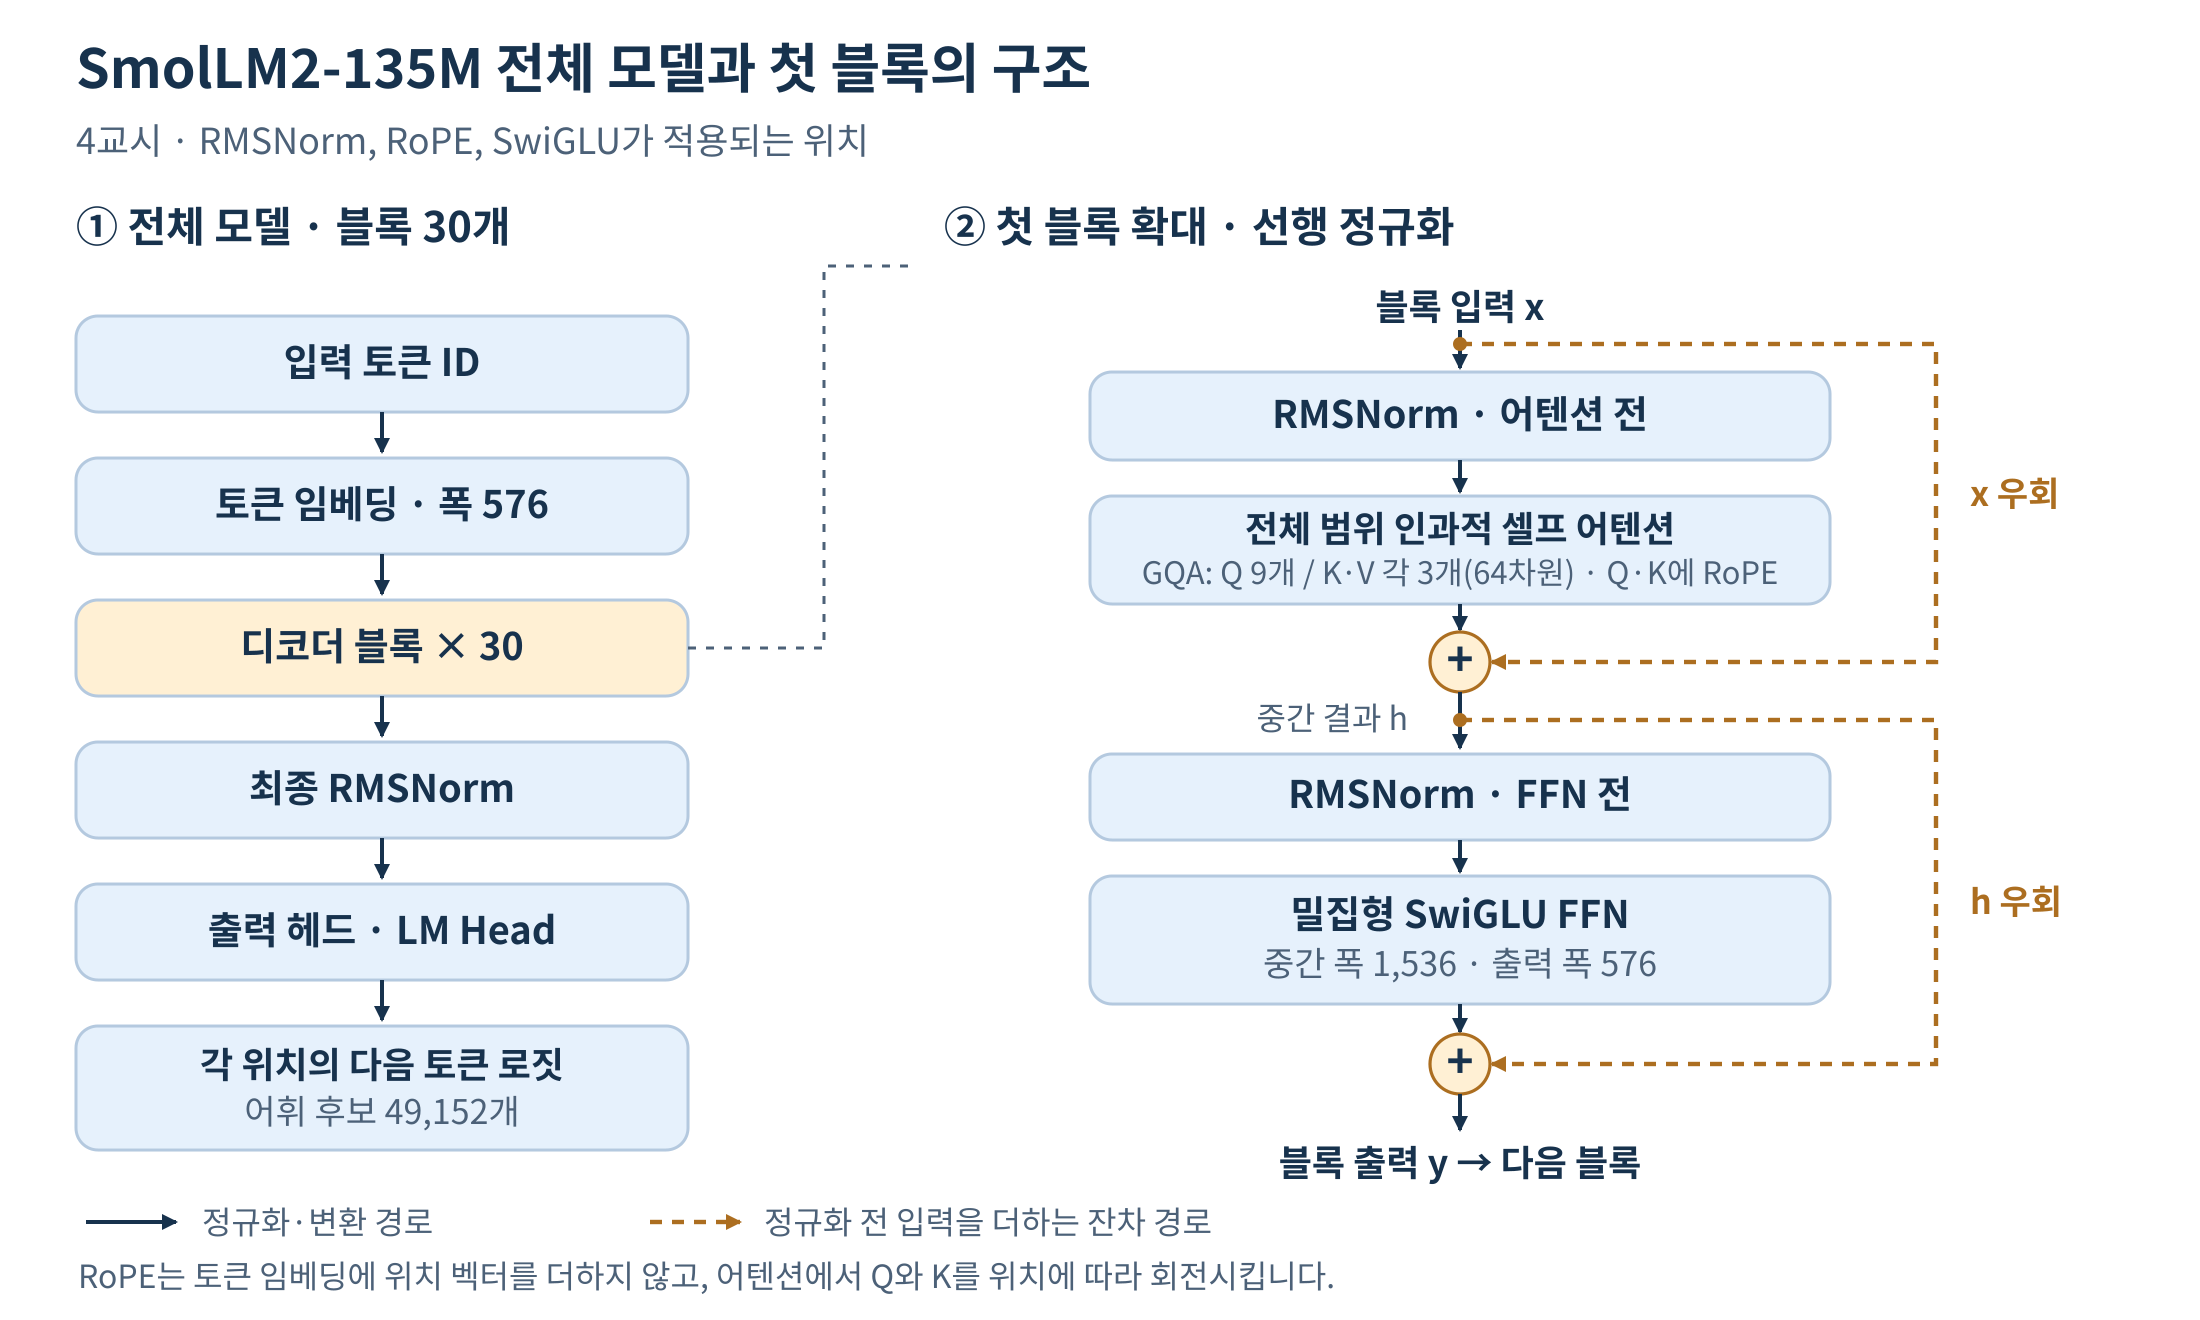

**전체 구조 설명:** 왼쪽은 토큰 입력부터 로짓까지의 전체 흐름입니다. 토큰 임베딩이 만든 폭 576의 표현을 30개 디코더 블록이 차례로 처리하고, 마지막 RMSNorm과 언어 모델 출력층(LM Head)을 거쳐 위치마다 49,152개 후보의 점수를 만듭니다. 오른쪽은 그중 첫 블록을 확대한 그림입니다. 어텐션과 SwiGLU 앞에 각각 RMSNorm이 있으며, GQA는 Q 9개 헤드가 K·V 3개 헤드를 공유합니다. RoPE는 어텐션 안에서 Q와 K에 적용하며 토큰 임베딩에 위치 벡터를 더하는 단계가 아닙니다. 점선으로 우회한 입력 `x`와 중간 표현 `h`는 각각 원형 `+`에서 변환 경로의 결과와 더해집니다. 두 잔차 합을 지난 뒤에도 표현 폭은 576이며, SwiGLU 내부 폭만 1,536으로 확장됩니다. 이 흐름을 이번 실습 문장에 적용한 로짓 모양 `(1, 6, 49152)`는 문장 1개·입력 6위치·어휘 후보 49,152개를 나타내며 생성한 토큰 수가 아닙니다.


## 2. 첫 블록의 실제 입력과 출력을 관찰하기
같은 영어 문장을 이 모델의 토크나이저로 읽습니다. 토크나이저가 달라졌으므로 GPT-2와 ID가 같을 필요는 없습니다. `(1, T, 576)`에서 1은 문장 수, T는 이번 토큰 수, 576은 위치별 표현의 폭입니다.

hook은 실제 계산을 잠시 관찰하는 장치입니다. 첫 RMSNorm의 입력·출력, FFN의 입력·출력, 회전 전 Q/K와 실제 사용한 회전 값을 보관합니다. 계산을 바꾸지 않고, 관찰이 끝나면 제거합니다. 전체 30개 블록을 통과했는지도 확인합니다.

### 코드 설명: 전체 모델은 실행하고 첫 블록은 자세히 관찰

이 셀은 문장 하나를 **전체 30개 블록**에 통과시키면서 첫 블록의 일부 입출력을 저장합니다. 다음 셀들은 여기서 관찰한 실제 값을 사용하여 RMSNorm·SwiGLU·RoPE 계산을 재구성합니다. 관찰을 위해 모델을 축소하거나 가중치를 변경하지 않습니다.

hook은 모듈 실행 시 호출되는 관찰 함수입니다. 값을 복사해 보관하지만 원래 출력을 교체하지 않습니다. 전체 블록의 방문 순서와 첫 블록의 상세 입출력을 구분하여 수집하고, 관찰 등록은 실행 후 해제합니다.


In [2]:
prompt = "The students learn AI today."
# 문자열을 ID와 유효 위치 마스크의 묶음으로 만듭니다. 인과 마스크는 모델 내부에 별도로 적용됩니다.
inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(device)
# 두 번째 축은 입력 토큰 수입니다. 문자 수나 단어 수와 항상 같지는 않습니다.
T = inputs["input_ids"].shape[1]
# 뒤의 위치 비교에 필요한 최소 길이와 모델이 지원하는 위치 범위를 확인합니다.
assert 2 <= T < model.config.max_position_embeddings
# hook으로 복사할 실제 중간값을 이름별로 보관합니다.
observed = {}
visited = []
# 이름을 기억하는 hook을 만들어 해당 모듈의 첫 입력과 출력을 함께 저장합니다.
def capture_io(name):
    def hook(module, args, output):
        # 실제 중간값을 별도 복사해 뒤의 재구성 비교에 사용합니다.
        observed[name + "_input"] = args[0].detach().clone()
        observed[name + "_output"] = output.detach().clone()
    return hook
# Q/K 선형 투영 직후의 출력만 저장합니다. 아직 회전 전입니다.
def capture_projection(name):
    def hook(module, args, output):
        observed[name] = output.detach().clone()
    return hook
# 실행 직전 키워드 인자에서 실제 사용한 cos·sin을 꺼냅니다.
def capture_attention(module, args, kwargs):
    # 이 값을 받으려면 등록할 때 with_kwargs=True가 필요합니다.
    cos, sin = kwargs["position_embeddings"]
    observed["cos"] = cos.detach().clone()
    observed["sin"] = sin.detach().clone()
# 블록 번호를 기억하는 함수를 반환하여 전체 실행 순서를 기록합니다.
def capture_block(index):
    def hook(module, args, output):
        visited.append(index)
    return hook
# 등록 반환값은 해제용 handle입니다. 관찰 함수는 원래 출력을 바꾸지 않습니다.
handles = [first.input_layernorm.register_forward_hook(capture_io("norm")),
           first.mlp.register_forward_hook(capture_io("mlp")),
           first.self_attn.q_proj.register_forward_hook(capture_projection("q_raw")),
           first.self_attn.k_proj.register_forward_hook(capture_projection("k_raw")),
           first.self_attn.register_forward_pre_hook(capture_attention, with_kwargs=True)]
# 첫 블록의 상세 관찰과 별개로 모든 블록의 방문을 기록합니다.
handles += [block.register_forward_hook(capture_block(i)) for i, block in enumerate(model.model.layers)]
try:
    # 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
    with torch.inference_mode():
        # 입력 묶음을 이름 있는 인자로 펼칩니다. logits는 위치별 어휘 점수입니다.
        result = model(**inputs, use_cache=False)
# 실행에 실패해도 hook을 제거하여 다음 실행 때 중복 관찰을 막습니다.
finally:
    for handle in handles:
        handle.remove()
# 전체 30개 블록의 순서를 검사하며 첫 블록만 실행한 것이 아님을 확인합니다.
assert visited == list(range(30))
assert result.logits.shape == (1, T, 49152)
assert observed["norm_input"].shape == observed["mlp_input"].shape == (1, T, 576)
print("Prompt:", repr(prompt))
print("IDs:", inputs["input_ids"][0].tolist())
print("Token pieces:", [repr(tokenizer.decode([i])) for i in inputs["input_ids"][0].tolist()])
print("T:", T, "visited blocks:", len(visited), "logits:", tuple(result.logits.shape))
print("Norm input / MLP input:", tuple(observed["norm_input"].shape), tuple(observed["mlp_input"].shape))
print("[PASS] 실제 전체 30블록 forward와 첫 블록 관찰")

Prompt: 'The students learn AI today.'
IDs: [504, 1058, 835, 5646, 1834, 30]
Token pieces: ["'The'", "' students'", "' learn'", "' AI'", "' today'", "'.'"]
T: 6 visited blocks: 30 logits: (1, 6, 49152)
Norm input / MLP input: (1, 6, 576) (1, 6, 576)
[PASS] 실제 전체 30블록 forward와 첫 블록 관찰


### 출력 설명: 30개 블록에서 무엇을 확인했나요?

- 같은 문장이 여섯 조각으로 복원되지만 ID는 앞 교시 GPT-2와 다릅니다. 토큰 ID는 모델별 어휘의 번호이므로 서로 다른 토크나이저 사이에서 숫자 자체를 비교하지 않습니다.
- `(1, 6, 49152)`는 문장 1개, 위치 6개 각각에서 어휘 후보 49,152개의 점수를 냈다는 뜻입니다. 방문한 30개 블록은 hook의 기록 순서까지 검사한 값으로, 첫 블록만 따로 실행한 결과가 아닙니다.
- Norm 입력과 MLP 입력은 둘 다 `(1, 6, 576)`이지만 같은 **값**이라는 뜻은 아닙니다. 블록의 서로 다른 지점에서 수집한 배열입니다. PASS는 전체 실행과 이 관찰 모양을 확인하며, 다음 두 셀에서 각각 대응하는 실제 출력과 비교합니다.


## 3. RMSNorm: 평균을 빼지 않고 크기를 정돈하기

RMSNorm은 평균을 빼는 대신, **토큰 하나를 나타내는 벡터의 크기**를 기준으로 각 값을 조절합니다.

**왜 평균을 빼는 단계를 생략할까요?** GPT-2의 층 정규화(LayerNorm)는 먼저 평균을 빼서 표현의 중심을 옮기고, 크기도 맞춥니다. RMSNorm을 제안한 연구는 **크기를 맞추는 효과만 남겨도 충분한 경우가 있는지** 살폈습니다. 예를 들어 `[2, 4]`가 통째로 두 배가 되어 `[4, 8]`이 되면 RMS도 두 배가 됩니다. 두 벡터를 각각 자신의 RMS로 나누면 같은 결과가 나옵니다(아래 작은 안정화 상수 ε의 영향은 제외). 반대로 모든 성분에 같은 값을 *더한* 경우까지 같아지는 것은 아닙니다. 제안 논문의 여러 실험에서는 평균 계산과 뺄셈을 생략하고도 LayerNorm과 비슷한 성능을 보였습니다. 이는 정규화 연산을 단순화한 선택이지, 어떤 모델에서나 반드시 더 빠르다는 뜻은 아닙니다. [Zhang·Sennrich의 RMSNorm 논문](https://arxiv.org/abs/1910.07467)

`yᵢ = γᵢ × xᵢ / √(mean(x²) + ε)`

1. **벡터의 크기를 구합니다.** `mean(x²)`는 각 성분을 먼저 제곱한 뒤 평균을 낸 값입니다. 여기에 0으로 나누는 것을 막는 작은 상수 `ε`(엡실론)를 더하고 제곱근을 구합니다. `ε`이 없을 때 이 값이 제곱평균제곱근(root mean square, RMS)입니다.
2. **같은 값으로 나눕니다.** 모든 입력 성분 `xᵢ`를 1단계에서 구한 값으로 나눕니다. 층 정규화(LayerNorm)와 달리, 각 성분에서 입력 평균을 빼지는 않습니다.
3. **성분별 가중치를 곱합니다.** 나눈 결과에 그 성분의 학습된 가중치 `γᵢ`(감마)를 곱하면 출력 `yᵢ`가 됩니다.

예를 들어 `[2, 2]`의 RMS는 `√((4 + 4) / 2) = 2`입니다. 이해를 위해 `ε`은 0, 가중치는 모두 1로 놓으면, 두 값을 2로 나눈 결과는 `[1, 1]`입니다. **값의 크기는 줄었지만 평균은 0이 아니라 1입니다.** 실제 계산에서는 `ε`을 더하고 학습된 가중치를 곱하므로 최종 출력의 RMS도 반드시 1이 되는 것은 아닙니다.

첫 번째 블록의 RMSNorm에 실제로 들어간 입력과 학습된 가중치를 가져옵니다. 위 식으로 직접 계산한 결과가 모델 출력과 일치하는지 확인합니다.


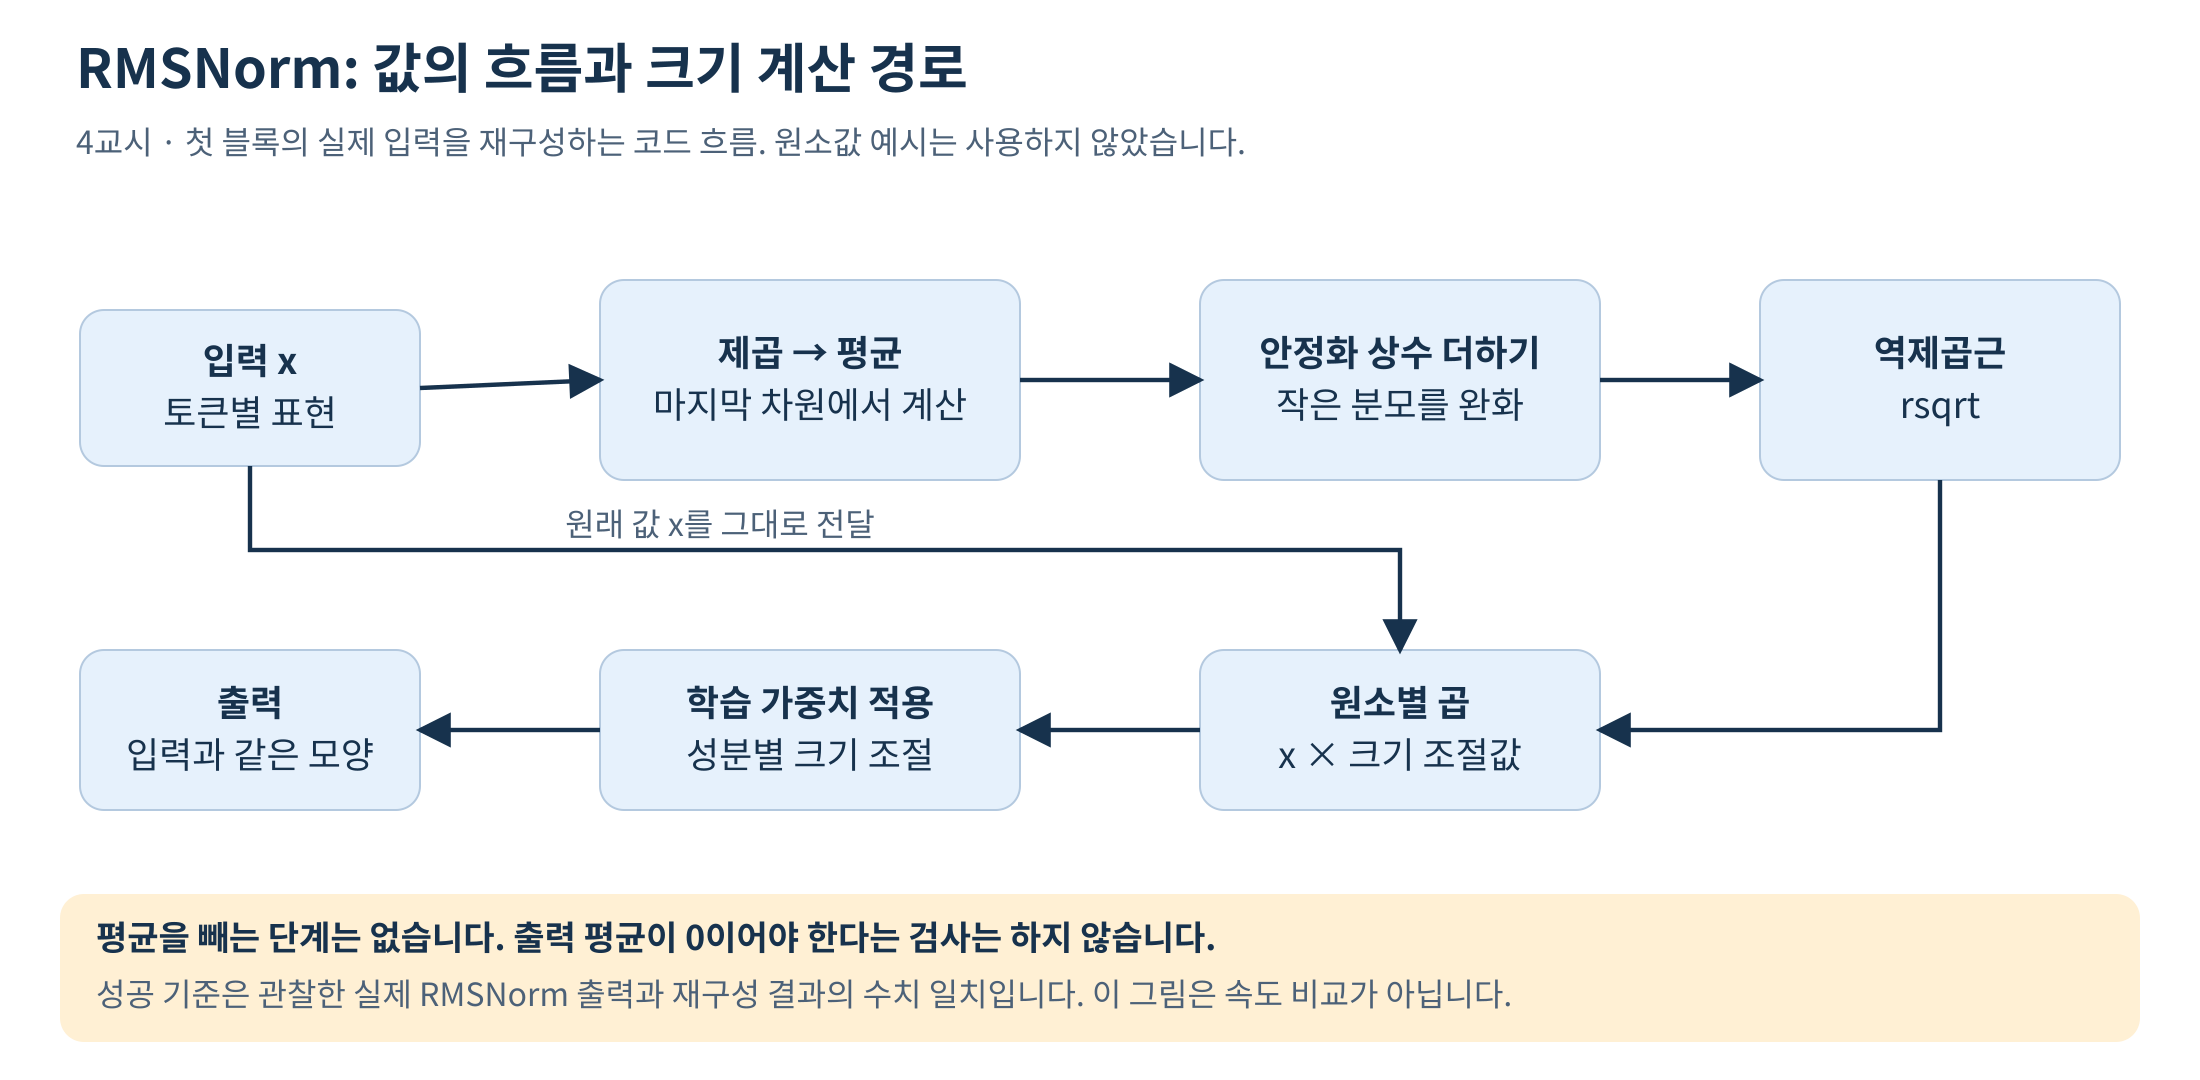

**그림 설명:** 원래 입력을 공통 분모로 나눈 뒤 각 성분에 해당하는 가중치를 곱합니다. 코드에서는 분모의 역수인 `torch.rsqrt(...)`를 곱해 같은 계산을 합니다.


### 코드 설명: RMSNorm이 실제로 계산한 값 재구성

이번 셀은 **첫 블록의 RMSNorm에 실제로 들어갔던 입력**에 같은 수식과 학습 가중치를 적용하여, 실제 모듈의 출력과 비교합니다. 새로운 예제 벡터를 만들거나 정규화 모듈을 임의로 바꾸는 실험이 아닙니다. 앞 셀에서 전체 모델을 한 번 실행하며 저장한 `observed`를 그대로 사용하므로 앞 셀부터 순서대로 실행해야 합니다.

RMSNorm은 각 토큰의 표현에서 제곱 평균을 구해 크기를 조절합니다. LayerNorm과 달리 입력의 평균을 빼지 않습니다. 따라서 **출력 평균이 0인지**가 아니라 **직접 재구성한 값과 실제 모듈 출력이 같은지**를 확인합니다. 이 실습은 계산 원리를 확인하는 것이며 속도나 모델 품질을 비교하지 않습니다.

**수치 비교 기준: RMSNorm 재구성의 비교**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

기준은 두 번째 인자인 실제 모듈 출력 `observed["norm_output"]`이고 `atol=rtol=1e-5`입니다. 기준 성분이 0이면 0.00001, 절댓값이 2이면 0.00003까지 허용합니다(계산 설명용 예). 출력된 최대 절대 차이는 오차 요약이며, 각 성분은 자기 기준값의 크기에 따라 판정됩니다. epsilon의 설정 일치는 별도의 정확한 등호 검사로, 이 오차 허용과 다른 조건입니다.


In [3]:
# 실제 첫 블록의 RMSNorm 모듈을 참조합니다. 새 정규화 모듈을 만들지 않습니다.
norm = first.input_layernorm
# 관찰한 정규화 직전 값을 FP32로 준비하며 새 예제 벡터를 만들지 않습니다.
x = observed["norm_input"].float()
# 모듈이 사용하는 분모 안정화 상수입니다. 평균을 뺀 분산 계산은 하지 않습니다.
epsilon = norm.variance_epsilon
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 표현의 마지막 축에서 제곱 평균을 구하며 평균을 빼지는 않습니다.
    mean_square = x.pow(2).mean(dim=-1, keepdim=True)
    # rsqrt는 역제곱근입니다. 토큰별 크기 조절값을 표현 성분 전체에 적용합니다.
    normalized = x * torch.rsqrt(mean_square + epsilon)
    # 학습된 성분별 배율을 원소별로 곱합니다. 별도 평균 빼기·편향 더하기는 없습니다.
    reconstructed_norm = normalized * norm.weight
# 모든 위치·성분의 절대 차이 중 최댓값 하나를 Python 수로 꺼냅니다.
norm_delta = (reconstructed_norm - observed["norm_output"]).abs().max().item()
assert epsilon == model.config.rms_norm_eps
# 모양뿐 아니라 모든 성분의 값을 절대·상대 허용오차 안에서 대조합니다.
# 기준 b = observed['norm_output']; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(reconstructed_norm, observed["norm_output"], atol=1e-5, rtol=1e-5)
print("epsilon:", epsilon, "weight:", tuple(norm.weight.shape))
print("first-token mean before / after:", x[0, 0].mean().item(), observed["norm_output"][0, 0].mean().item())
print("RMSNorm reconstruction max difference:", norm_delta)
print("[PASS] 실제 RMSNorm 수식·학습 가중치·epsilon 일치")

epsilon: 1e-05 weight: (576,)
first-token mean before / after: -0.006252794060856104 0.0030134147964417934
RMSNorm reconstruction max difference: 0.0
[PASS] 실제 RMSNorm 수식·학습 가중치·epsilon 일치


### 출력 설명: 어느 숫자를 보면 실습이 성공한 걸까요?

- 가중치 `(576,)`는 토큰마다 별도 가중치를 갖는 것이 아니라 576개 표현 성분에 적용할 학습된 배율 하나씩을 뜻합니다. epsilon은 설정과 같은 0.00001로 사용했습니다.
- 첫 토큰의 평균은 약 −0.00625에서 0.00301로 바뀌었습니다. 출력 평균이 0이 아니어도 정상입니다. RMSNorm은 평균을 빼는 연산이 아니며, 학습된 성분별 배율도 적용하기 때문입니다.
- 재구성 최대 차이 0은 관찰한 모든 위치·성분에서 직접 계산한 값과 실제 모듈 출력이 이 기록에서 같았음을 뜻합니다. PASS는 설정 epsilon의 일치와 `allclose` 검사를 함께 통과한 결과입니다. 평균을 0으로 만드는 것을 성공 조건으로 삼지 않습니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 4. SwiGLU: 두 경로를 원소별로 곱하는 FFN

#### GPT-2에 없던 두 번째 경로는 무슨 일을 할까요?

피드포워드 신경망(feed-forward network, FFN)은 한 토큰의 표현을 받아 **그 토큰의 성분을 다시 조합합니다.** GPT-2 Small에서는 완전연결층(fully connected layer) `c_fc`가 표현을 768차원에서 3,072차원으로 넓히고, GELU를 적용한 뒤 `c_proj`가 다시 768차원으로 되돌립니다. **중간에 한 경로만 있고, 별도의 게이트와 곱하지 않습니다.** [GPT-2의 MLP 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt2/modeling_gpt2.py)

SmolLM2의 SwiGLU FFN은 같은 입력을 두 경로로 보냅니다. **값 경로**는 전달할 성분을 만들고, **게이트(gate) 경로**는 각 성분을 얼마나 조절할지 계산합니다. 예를 들어 값 경로의 한 성분이 4라면, 게이트가 0.5일 때는 2, 2일 때는 8, −0.25일 때는 −1이 됩니다. 게이트는 다른 토큰을 고르는 장치가 아니라 **현재 토큰 안에서 같은 위치의 성분에 곱하는 조절값**입니다. 입력이 달라지면 조절값도 달라집니다.

**왜 한 경로 대신 두 경로를 쓸까요?** 한 경로의 FFN은 넓힌 값에 활성화 함수를 바로 적용합니다. SwiGLU는 전달할 값과 그 값을 얼마나 조절할지를 **서로 다른 가중치로 계산**합니다. 값 경로의 성분이 비슷해도 입력에 따라 게이트가 달라져, 같은 성분을 더 약하게 또는 강하게 전달할 수 있습니다. 행렬이 하나 더 필요하지만 아래처럼 중간 폭을 줄이면 가중치 수를 맞춰 비교할 수 있습니다. 제안 논문의 T5 실험에서는 이렇게 예산을 맞춘 SwiGLU가 일반 ReLU·GELU FFN보다 검증 데이터의 퍼플렉서티(perplexity, 낮을수록 검증 토큰에 더 높은 확률을 부여했다는 뜻)가 낮았습니다. 한 실험의 결과이며 모든 모델에서 성능이 좋아진다는 보장은 아닙니다. [Shazeer의 GLU 변형 논문 §2–3](https://arxiv.org/pdf/2002.05202#page=2)

#### 먼저 SiLU부터: 게이트에 넣는 활성화 함수

**SiLU(Sigmoid Linear Unit, 시그모이드 선형 유닛)**는 숫자 하나를 받아 그 숫자와 자신의 시그모이드 값을 곱하는 활성화 함수입니다. 벡터에 적용할 때는 각 성분에 같은 계산을 따로 합니다. 여기서 `z`는 게이트 선형 투영이 만든 성분 하나입니다.

`σ(z) = 1 / (1 + exp(−z))`

`SiLU(z) = z × σ(z)`

시그모이드 `σ(z)`는 입력을 **0과 1 사이의 부드러운 값**으로 바꿉니다. SiLU는 그 값만 돌려주지 않고 **원래 입력 `z`를 한 번 더 곱합니다.** 그래서 음수를 모두 0으로 잘라내는 ReLU와 달리 작은 음수를 남길 수 있고, 큰 양수에서는 원래 입력에 가까워집니다. [PyTorch SiLU 공식 문서](https://docs.pytorch.org/docs/stable/generated/torch.nn.SiLU.html)

**SiLU가 ‘Swish의 β=1’이라는 말은 무슨 뜻일까요?** Swish는 시그모이드에 들어갈 값에 β(베타)를 곱합니다. 바깥에서 곱하는 입력 `z`는 그대로입니다.

- **Swish의 일반식:** `z × sigmoid(β × z)`
- **β = 1을 대입:** `z × sigmoid(1 × z) = z × sigmoid(z)` → **SiLU**

같은 `z = 1`을 넣어 보겠습니다. β가 1이면 시그모이드 안에 1이 들어가서 결과가 약 `0.731`입니다. β가 2이면 안에 2가 들어가서 약 `0.881`입니다. **아래 그림과 이 실습에서는 β = 1인 SiLU를 사용하므로 β를 따로 입력하거나 학습하지 않습니다.**

- `z = -1`: 시그모이드가 약 0.269이므로 SiLU는 약 −0.269입니다.
- `z = 0`: 시그모이드는 0.5지만 원래 입력 0을 곱하므로 SiLU는 0입니다.
- `z = 1`: 시그모이드가 약 0.731이므로 SiLU도 약 0.731입니다.

이 셋은 다음 손계산에 나오는 게이트 입력의 예입니다. **SiLU의 출력은 확률이 아닙니다.** 음수가 될 수 있고, 예를 들어 `z = 2`이면 약 1.762로 1보다 큽니다. 출력의 크기나 부호에 따라 값 경로의 성분을 줄이거나 키우거나 부호를 바꿀 수 있습니다.

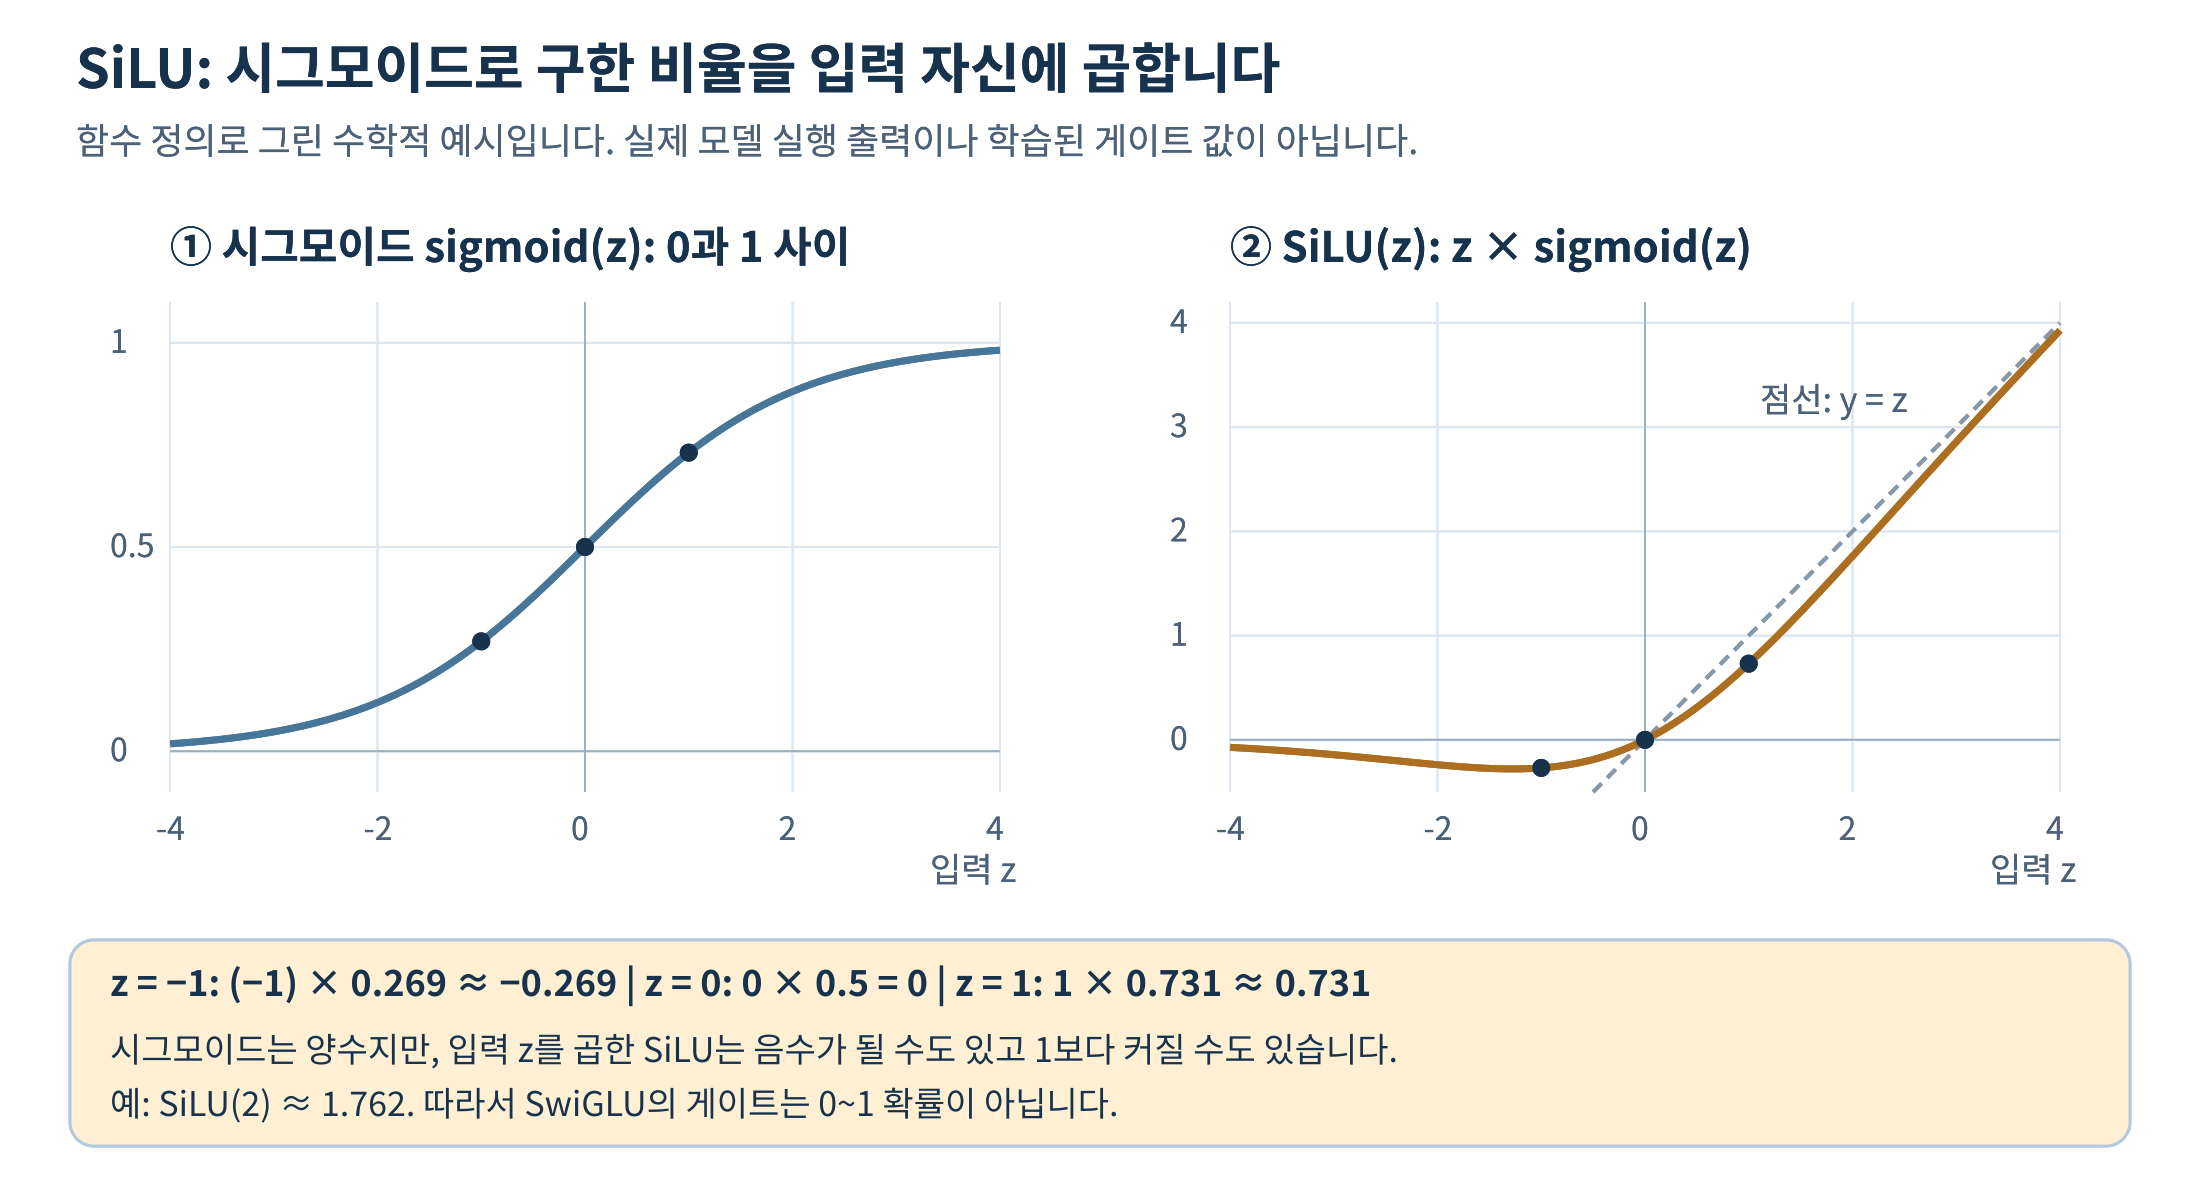

**그림 설명:** 왼쪽의 시그모이드 값에 원래 입력을 곱한 결과가 오른쪽 SiLU입니다. 오른쪽 점선은 비교용 `y = z`이며, 아래 숫자는 함수 정의에서 계산한 예이지 실습 모델의 출력이 아닙니다.

#### 숫자 두 개로 전체 경로를 따라가 봅시다

선형 투영(linear projection)은 **가중치 행 하나와 입력 벡터를 곱해 더해서 새 성분 하나를 만드는 연산**입니다. 입력이 두 성분이어도 가중치 행이 세 개라면 출력 세 성분을 만들 수 있습니다.

**작은 예: 입력 2개 → 두 경로에서 각각 3개 → 출력 2개.** 두 경로와 원소별 곱 구조를 유지한 손계산 예로 전체 흐름을 따라가 보겠습니다. 실제 모델이나 학습 가중치를 축소해 실행한 결과는 아닙니다.

1. **값 경로:** 입력 `[2, 3]`에 가중치 행 `[1, 0]`, `[0, 1]`, `[1, 1]`을 각각 내적해 `[2, 3, 5]`를 만듭니다. 세 번째 값은 `1×2 + 1×3 = 5`입니다.
2. **게이트 경로:** 같은 입력에 다른 가중치 행 `[0, 0]`, `[-1, 1]`, `[1, -1]`을 쓰면 `[0, 1, -1]`입니다. 여기에 SiLU를 각각 적용하면 약 `[0, 0.731, -0.269]`입니다.
3. **같은 위치끼리 곱하기:** 값 `[2, 3, 5]`에 게이트 `[0, 0.731, -0.269]`를 곱하면 약 `[0, 2.193, -1.345]`입니다. 첫 성분은 사라지고, 둘째는 크기가 줄고, 셋째는 부호가 바뀝니다. SiLU에 `2`가 들어가면 약 `1.762`가 되므로, 게이트가 1보다 크면 값의 크기를 키울 수도 있습니다.
4. **출력 투영:** 곱셈 결과에 두 행 `[1, 0, 1]`, `[0, 1, 1]`을 적용합니다. 첫 출력은 첫째와 셋째를 더해 약 `-1.345`, 둘째는 둘째와 셋째를 더해 약 `0.848`입니다. **앞의 두 성분만 잘라내거나 원래의 [2, 3]을 복원하는 것이 아니라, 세 값을 다시 섞어 새 성분 두 개를 만듭니다.**

이 숫자는 원리를 보여 주는 손계산 예입니다. 코드 셀에서는 모형 가중치가 아니라 실제 모델의 학습된 가중치를 사용합니다.

#### 두 경로를 이해했다면, 이제 SwiGLU라는 이름을 읽어 봅시다

게이트 선형 유닛(Gated Linear Unit, GLU)은 게이트 경로에 시그모이드(sigmoid)를 적용합니다. **SwiGLU는 그 자리에 Swish를 쓰는 GLU**입니다. 이 실습에서는 앞에서 본 β = 1인 Swish, 즉 SiLU로 게이트를 계산합니다. [Shazeer의 GLU 변형 논문 §2](https://arxiv.org/pdf/2002.05202#page=2)

`output = down_proj(SiLU(gate_proj(x)) ⊙ up_proj(x))`

여기서 `⊙`는 두 벡터의 **같은 위치끼리 곱하는 원소별 곱(element-wise multiplication)**입니다.

#### 실제 모델에서는 576 → 1,536 → 576입니다

손계산 예에서는 입력과 출력 폭이 2, 중간 폭이 3이었습니다. SmolLM2-135M에서는 2 대신 576, 3 대신 1,536을 사용합니다. **이 모델의 `torch.nn.Linear`에서 가중치 모양은 (출력 폭, 입력 폭)**입니다.

| 선형층 | 가중치 모양 (출력, 입력) | 한 토큰에서 하는 일 |
|---|---|---|
| `up_proj`, `gate_proj` | 각각 `(1536, 576)` | 같은 576개 입력에서 서로 다른 가중치로 각각 1,536개 성분을 만듭니다. |
| `down_proj` | `(576, 1536)` | 원소별 곱으로 얻은 1,536개 성분을 다시 섞어 새 성분 576개를 만듭니다. |

**가중치 저장 방향 주의:** 위 표는 SmolLM2의 `torch.nn.Linear` 기준입니다. 앞서 본 GPT-2의 `c_fc`·`c_proj`는 Hugging Face의 `Conv1D` 클래스로 선형 변환을 구현하며, 가중치를 `(입력 폭, 출력 폭)`으로 저장합니다. 따라서 두 구현의 `weight.shape`를 같은 축 순서로 읽으면 안 됩니다. 변환의 입력·출력 역할은 같고 저장 방향이 다릅니다. [PyTorch Linear 문서](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html) · [Transformers Conv1D 문서](https://huggingface.co/docs/transformers/en/internal/modeling_utils#transformers.Conv1D)

토큰 수는 그대로이고 **토큰당 표현 폭만** 바뀝니다. 마지막에 폭을 576으로 되돌려야 FFN 입력과 같은 모양이 되어 잔차 연결(residual connection)에서 더할 수 있습니다.

#### 왜 중간 폭은 1,536일까요?

576의 정수 배일 필요는 없습니다. **같은 가중치 수로 일반 FFN과 비교**하면 1,536을 이해하기 쉽습니다. 표현 폭이 576이고 중간 폭을 4배로 둔 일반 FFN에는 `576 → 2304`와 `2304 → 576`의 행렬 두 개가 있습니다. SwiGLU에는 값·게이트·출력 투영에 행렬이 세 개 필요합니다.

- 일반 FFN: `2 × 576 × 2304 = 2,654,208`
- SwiGLU: `3 × 576 × 1536 = 2,654,208`

편향(bias)을 제외한 **한 블록의 FFN 가중치 수**입니다. 행렬이 2개에서 3개로 늘 때 폭을 `2304 × 2/3 = 1536`으로 줄이면 수가 맞습니다. [Shazeer (2020) §2–3.1](https://arxiv.org/pdf/2002.05202#page=2)도 비교 실험에 이 방식으로 폭을 조정했습니다. [SmolLM2-135M 공개 설정](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json)의 1,536은 이 계산과 일치합니다. **가중치 수로 폭을 설명한 것이며, 제작진이 공개한 이 숫자의 선정 사유나 실제 속도가 같다는 뜻은 아닙니다.**

이제 그림에서 **같은 입력이 어디서 갈라지고, 두 경로가 어디서 곱해지며, 어느 층이 폭을 576으로 되돌리는지** 찾아보세요.


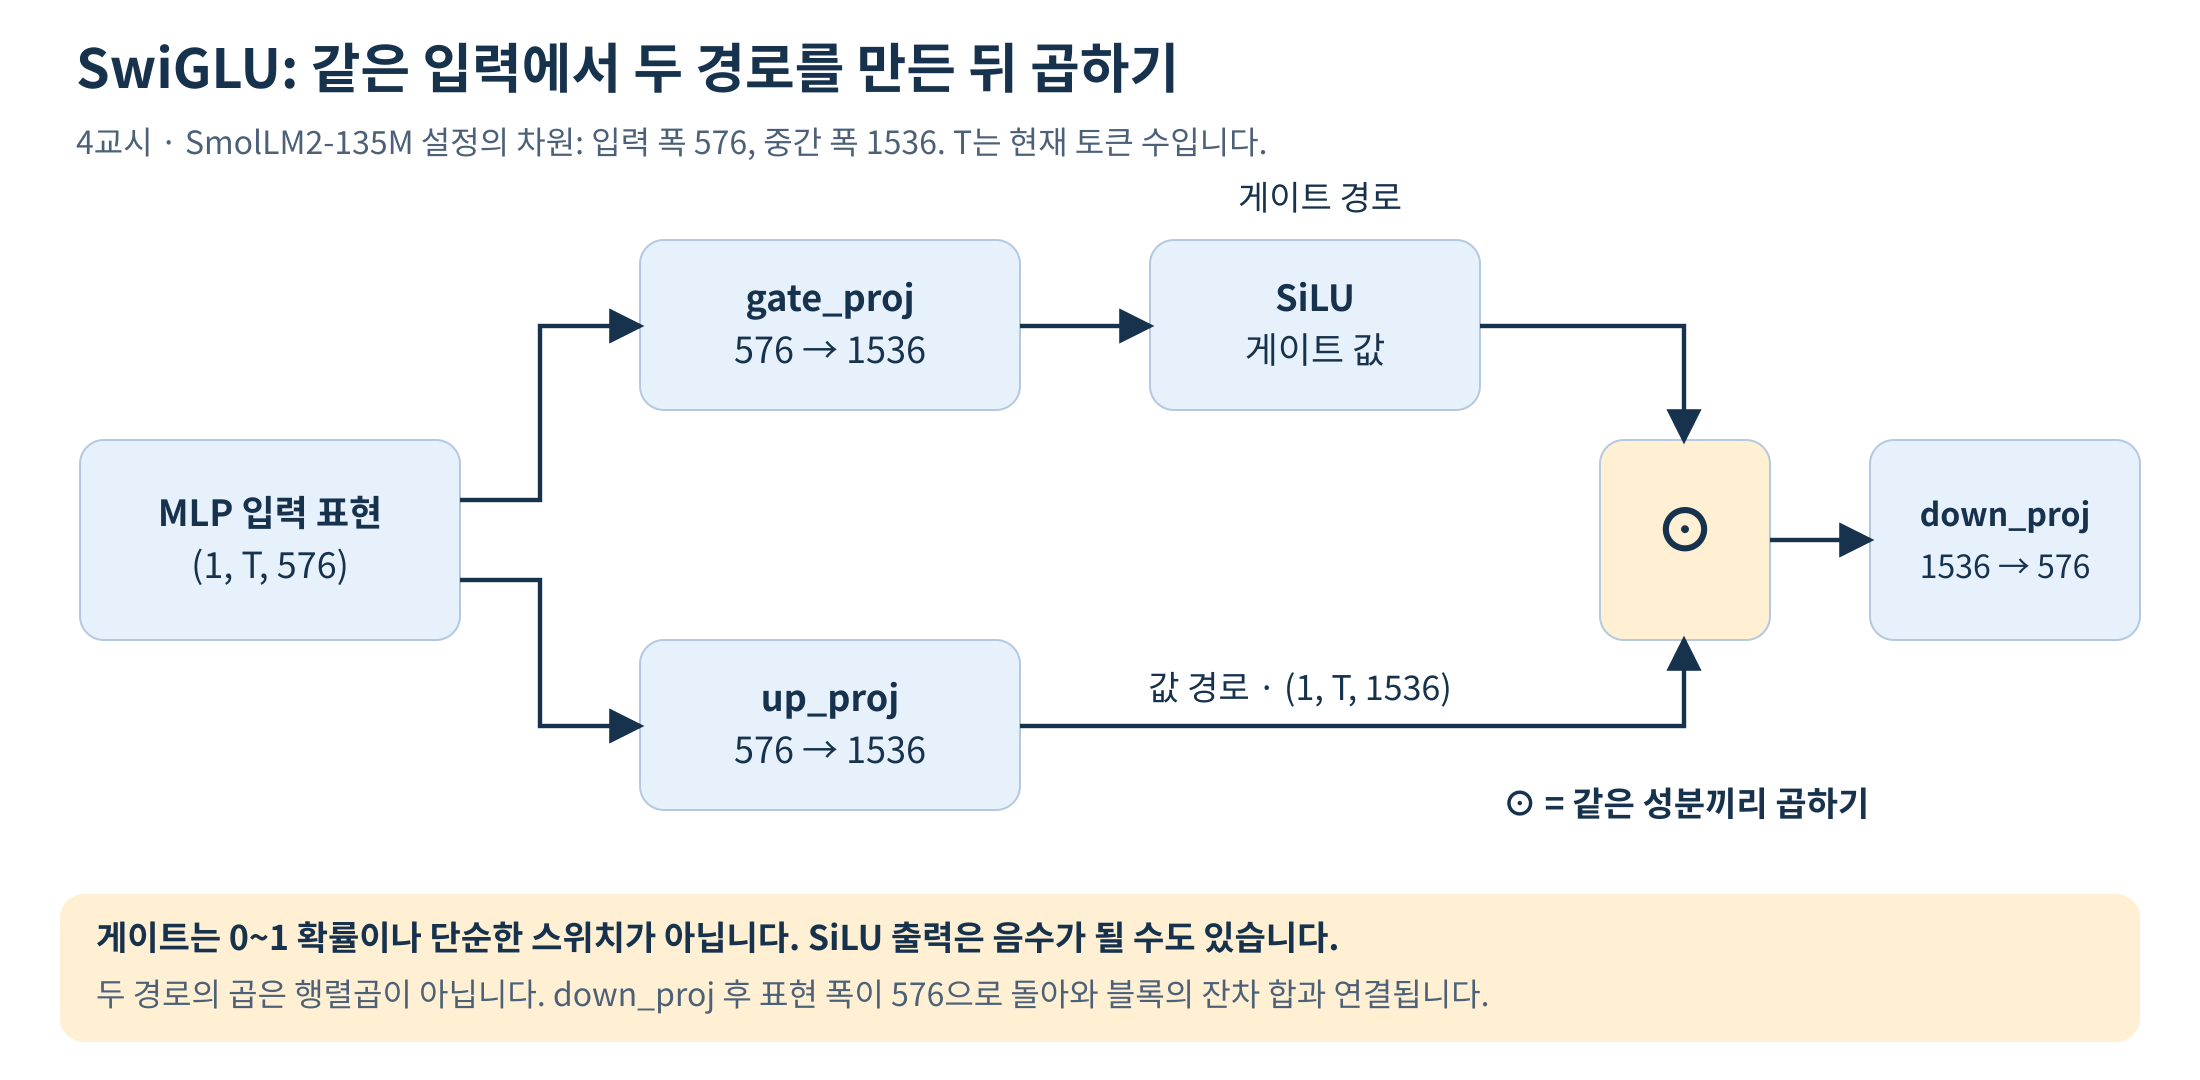

**그림 설명:** 같은 입력이 두 경로로 갈라지고, 폭이 같은 두 결과가 원소별 곱으로 합쳐집니다. 마지막에 폭만 576으로 돌아옵니다.


### 코드 설명: SwiGLU의 두 경로와 한 번의 복귀

이번 셀은 첫 블록의 실제 MLP 입력을 두 경로로 나누어 계산하고, 그 결과를 합쳐 원래 표현 폭으로 되돌립니다. 같은 입력을 쓰더라도 **서로 다른 학습 가중치**를 통과하므로 두 경로의 값은 다릅니다. 하나는 값을 조절할 게이트, 다른 하나는 조절받을 중간 표현을 만듭니다.

여기서 **게이트(gate)**는 입력에 따라 정보를 조절하는 수치입니다. 0과 1 사이의 확률이나 단순한 켜기·끄기 스위치가 아닙니다. 또한 이 블록은 Dense FFN이므로 게이트가 여러 MoE 전문가 중 하나를 선택하는 것도 아닙니다. 이 실습은 학습된 MLP의 계산 경로를 재구성하여 확인하며, 단순 FFN보다 무조건 빠르거나 가볍다는 것을 입증하지는 않습니다.

**수치 비교 기준: 활성 함수와 MLP 재구성의 비교**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

게이트 비교는 실제 활성 함수 결과 `mlp.act_fn(gate_linear)`가 기준이며 `atol=rtol=1e-6`입니다. 최종 MLP 비교는 `observed["mlp_output"]`가 기준이고 `atol=rtol=1e-5`입니다. 기준 성분의 절댓값이 2라면 각각 0.000003과 0.00003을 허용합니다(계산 설명용 예). 두 비교의 허용오차가 같지 않으며, 출력된 MLP 최대 차이는 두 번째 비교의 요약입니다.


In [4]:
mlp = first.mlp
# 정규화 실습 입력과 다른 관찰 지점입니다. MLP 직전의 실제 값을 씁니다.
x_mlp = observed["mlp_input"]
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 게이트 경로에서 표현 폭을 576 → 1536으로 넓힙니다.
    gate_linear = mlp.gate_proj(x_mlp)
    # SiLU는 z*sigmoid(z)이며 음수 또는 1보다 큰 값도 가능합니다.
    gate = F.silu(gate_linear)
    # 원래 MLP 입력에서 별도로 출발하는 값 경로입니다. gate 출력을 입력받지 않습니다.
    up = mlp.up_proj(x_mlp)
    # 행렬곱이 아니라 같은 위치·성분의 값을 곱해 게이트를 적용합니다.
    product = gate * up
    # 폭을 576으로 되돌립니다. 잔차 덧셈 전 MLP 출력과 비교합니다.
    reconstructed_mlp = mlp.down_proj(product)
assert gate.shape == up.shape == product.shape == (1, T, 1536)
assert reconstructed_mlp.shape == (1, T, 576)
# 기준 b = mlp.act_fn(gate_linear); 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(gate, mlp.act_fn(gate_linear), atol=1e-6, rtol=1e-6)
# 모양뿐 아니라 모든 성분의 값을 절대·상대 허용오차 안에서 대조합니다.
# 기준 b = observed['mlp_output']; 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(reconstructed_mlp, observed["mlp_output"], atol=1e-5, rtol=1e-5)
mlp_delta = (reconstructed_mlp - observed["mlp_output"]).abs().max().item()
print("gate / up / product:", tuple(gate.shape), tuple(up.shape), tuple(product.shape))
print("down output:", tuple(reconstructed_mlp.shape))
print("gate min / max:", gate.min().item(), gate.max().item())
print("SwiGLU reconstruction max difference:", mlp_delta)
print("[PASS] 실제 SwiGLU 세 행렬과 원소별 곱 일치")

gate / up / product: (1, 6, 1536) (1, 6, 1536) (1, 6, 1536)
down output: (1, 6, 576)
gate min / max: -0.2781923711299896 2.3255627155303955
SwiGLU reconstruction max difference: 0.0
[PASS] 실제 SwiGLU 세 행렬과 원소별 곱 일치


### 출력 설명: 두 경로를 곱한 뒤 폭이 어떻게 바뀌나요?

- gate·up·product가 모두 `(1, 6, 1536)`인 것은 두 분기의 같은 위치·성분끼리 곱했기 때문입니다. 곱한다고 폭이 제곱되거나 토큰 수가 늘지 않습니다. down 출력의 `(1, 6, 576)`에서 잔차 경로에 더할 수 있는 원래 표현 폭으로 돌아옵니다.
- gate의 최솟값은 약 −0.278, 최댓값은 약 2.326입니다. SiLU를 지난 게이트는 음수도 1보다 큰 수도 가질 수 있으므로 0~1 확률이나 켜짐/꺼짐 표시로 읽으면 안 됩니다. 이 범위는 이번 입력에서 관찰한 범위이지 SiLU의 전체 출력 범위가 아닙니다.
- 재구성 최대 차이 0과 PASS는 `SiLU(gate_proj(x)) * up_proj(x)` 뒤 `down_proj`를 적용한 값이 실제 MLP 출력과 일치했음을 뜻합니다. 세 행렬의 모양뿐 아니라 계산 경로를 함께 확인한 것입니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-06, rtol=1e-06`, `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 5. RoPE: Q와 K를 위치에 따라 회전하기

**회전해서 얻는 것부터 살펴봅시다.** 문장 속 현재 토큰의 Q(쿼리, query)가 한 칸 앞 K₁과 두 칸 앞 K₂를 비교한다고 해 보겠습니다. 두 후보의 위치만 다르게 하고, 회전 전 Q와 두 K(키, key)는 모두 `(1, 0)`으로 놓습니다. **회전하지 않으면** 두 후보의 내적(dot product)은 모두 `1`입니다. 이 비교에는 위치가 들어 있지 않으므로 어느 후보가 한 칸 앞인지 점수만으로는 구분할 수 없습니다.

**회전 위치 임베딩(rotary position embedding, RoPE)을 적용하면** 한 칸 앞과 두 칸 앞이라는 차이가 점수에 반영될 수 있습니다. 한 칸당 30°씩 도는 손계산 예에서 위치 2의 Q는 60°, 위치 1의 K₁은 30°, 위치 0의 K₂는 0°를 향합니다. 길이가 모두 1이므로 내적은 두 화살표 사이 각도의 코사인입니다. 한 칸 앞 후보는 `cos 30° ≈ 0.866`, 두 칸 앞 후보는 `cos 60° = 0.500`입니다. **회전 전에는 동점이었지만, 이제는 위치 관계가 점수에 차이를 만듭니다.** 이 내적은 소프트맥스(softmax) 전 어텐션 점수 계산에 쓰이므로, 각 후보의 V(값, value)를 얼마나 섞을지에도 영향을 줄 수 있습니다.

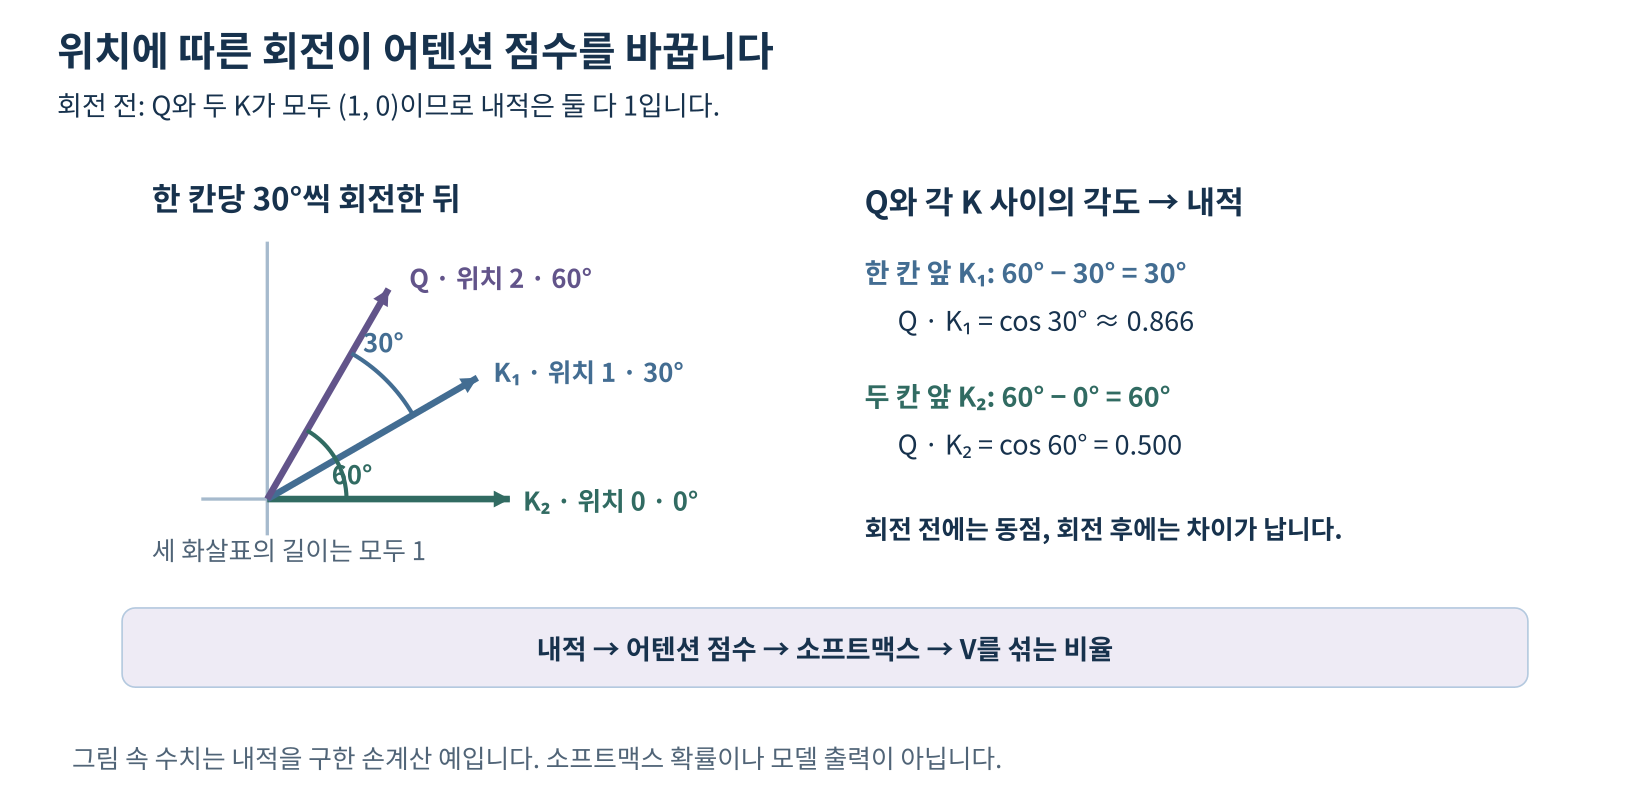

**그림 설명:** 보라색 Q를 기준으로 파란색 K₁과는 30°, 초록색 K₂와는 60° 벌어져 있습니다. 두 내적의 차이는 어텐션 점수를 거쳐 V를 섞는 비율에 반영될 수 있습니다.

두 후보의 앞섬을 구별하는 이 예는 **가까울수록 항상 점수가 높다는 규칙이 아닙니다.** 실제 점수에는 Q·K에 담긴 내용과 여러 성분 쌍의 회전이 함께 반영됩니다. 또한 ‘회전하지 않으면 동점’은 다른 위치 정보도 주지 않은 이 손계산 예의 조건이지, GPT-2가 순서를 구별하지 못한다는 뜻이 아닙니다.

**그렇다면 모델은 위치 정보를 어디에 넣을까요?** GPT-2는 토큰 임베딩(token embedding)에 학습된 위치 벡터를 더한 다음 Q·K·V를 만듭니다. SmolLM2의 회전 위치 임베딩(rotary position embedding, RoPE)은 블록의 어텐션 안에서 Q(쿼리, query)와 K(키, key)를 만든 **다음**, 두 벡터를 각자의 토큰 위치에 맞춰 회전시킵니다. V(값, value)는 이 회전을 하지 않습니다. 회전된 Q와 K의 내적(dot product)이 어텐션 점수의 바탕이 됩니다.

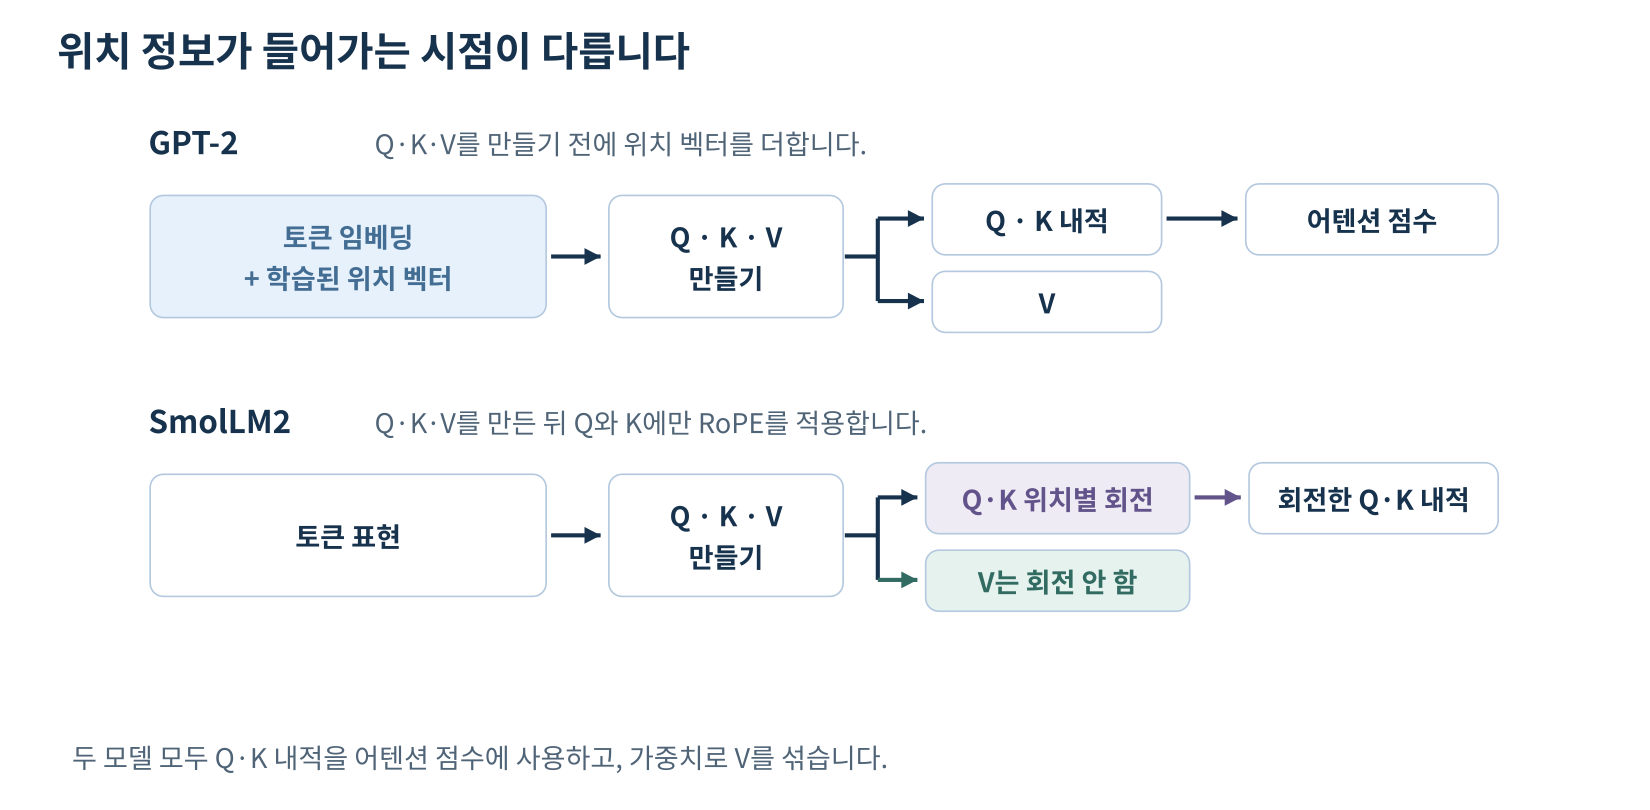

**그림 설명:** 위쪽의 파란 상자는 위치 벡터를 더하는 곳이고, 아래쪽의 보라 상자는 Q와 K를 각자의 위치에 맞춰 회전하는 곳입니다. SmolLM2에서 V는 보라 상자를 거치지 않습니다.

**무엇을 회전시킬까요?** 입력 문장의 토큰 하나, 그중에서도 위치 번호가 2인 **세 번째 토큰**에 주목해 봅시다. SmolLM2에서 이 토큰이 디코더 블록에 들어오면 블록이 받은 토큰의 은닉 표현(hidden representation)을 RMSNorm으로 정리한 뒤, 학습된 쿼리 투영(query projection, `q_proj`)으로 Q를 만듭니다. 모델이 만든 Q를 여러 어텐션 헤드(attention head)로 나누고, 여기서는 **첫 번째 헤드의 Q 벡터 하나만** 꺼내 봅니다.

> 세 번째 토큰의 블록 내 표현 → RMSNorm → `q_proj` → 첫 번째 헤드의 Q 벡터 → RoPE → 회전한 Q를 K와 비교

**8개 숫자는 무엇인가요?** 실제 SmolLM2에서는 이 Q 벡터에 성분이 64개 들어 있습니다. 손으로 계산하기 쉽게 이번 예시에서만 헤드의 폭을 8로 줄이고, RoPE를 적용하기 직전 Q가 `(1, 1, 1, 1, 0, 0, 0, 0)`이라고 가정합니다. 이 숫자는 토큰 8개의 번호나 입력 임베딩이 아니라, **한 토큰에서 만든 한 헤드의 Q 벡터에 들어 있는 8개 좌표값**입니다. 실제 모델에서 읽거나 64개 중 앞의 8개를 잘라 온 값이 아닙니다.

**이 손계산의 목표는 무엇인가요?** 앞에서는 회전한 Q와 K의 각도가 어텐션 점수에 영향을 준다는 것을 봤습니다. 이번에는 그 점수를 계산하기 **바로 전**, Q가 어떻게 회전하는지 확인합니다. 한 번의 평면 회전에는 가로·세로 좌표 두 개가 필요하므로, 이 구현의 방식대로 앞뒤 절반에서 같은 순서의 성분을 골라 `(0, 4)`, `(1, 5)`, `(2, 6)`, `(3, 7)`의 네 쌍을 만듭니다. 괄호 속 숫자는 **성분 번호**입니다. 예를 들어 0번 값은 1이고 4번 값은 0이므로 첫째 쌍의 좌표는 `(1, 0)`입니다. 나머지 쌍도 같은 좌표에서 출발하도록 값을 정했으니, 회전 후에 생기는 차이는 쌍마다 다른 회전각 때문임을 확인할 수 있습니다. K도 각자의 토큰 위치에서 같은 절차를 따르지만, 여기서는 Q 한 벡터만 계산합니다.

**① 뒤쪽 쌍의 회전각은 왜 작을까요?** 이 예에서는 [RoFormer의 기본 각도 규칙](https://arxiv.org/html/2104.09864#S3.SS2)인 `ωᵢ = 10000^(−2i/d_head)`를 씁니다. `i`는 0부터 세는 쌍 번호, `d_head`는 한 헤드의 차원입니다. 8차원에서는 `ωᵢ = 1 / 10000^(i/4)`이므로, `i`가 1씩 늘 때마다 분모가 10배로 커집니다. 따라서 뒤쪽 쌍은 앞 쌍의 정확히 1/10만큼 돕니다. 위치가 2인 토큰의 실제 회전각은 한 칸당 각도에 2를 곱한 `αᵢ = 2 × ωᵢ`입니다. 앞서 본 Transformer의 사인·코사인 위치 인코딩과 각도 간격을 정하는 식은 닮았지만, 여기서는 모델 전체 폭 512가 아니라 **헤드의 회전 차원 8**을 쓰고, 그 각도로 Q·K의 성분 쌍을 돌립니다.

**② 각도가 정해지면 새 좌표는 어떻게 구할까요?** 이 식은 **사인·코사인 덧셈정리 (angle addition formulas)**에서 나옵니다. 벡터의 길이를 `r`, 가로축에서 잰 **회전 전 방향각**을 `θ`라고 하면 원래 좌표는 `x = r cos θ`, `y = r sin θ`입니다. 이 벡터를 반시계 방향으로 `α`만큼 돌려도 길이는 `r` 그대로이고, 방향각만 `θ + α`가 됩니다. 이때 `θ`는 원래 방향이고, `α`는 RoPE가 추가로 돌리는 각도입니다.

1. **새 가로 좌표:** `x′ = r cos(θ + α)`  
   코사인 덧셈정리를 적용하면 `r cos θ cos α − r sin θ sin α`입니다. `r cos θ = x`, `r sin θ = y`를 넣으면 **`x′ = x cos α − y sin α`**가 됩니다.
2. **새 세로 좌표:** `y′ = r sin(θ + α)`  
   사인 덧셈정리를 적용하면 `r sin θ cos α + r cos θ sin α`입니다. 같은 값을 넣으면 **`y′ = x sin α + y cos α`**가 됩니다.

이 손계산에서 각 쌍의 시작 좌표는 `(1, 0)`입니다. 즉, 길이는 `1`이고 방향각은 `0`이므로, 회전 후 좌표는 곧 `(cos α, sin α)`입니다. 다음 풀이에서 첫째와 둘째 쌍의 `α`를 각각 넣어 확인합니다.

첫째 쌍 `(0번, 4번)`은 값이 `(1, 0)`이고 `α₀ = 2 × 1 = 2` 라디안입니다. 따라서 `x′ = 1 × cos 2 − 0 × sin 2 ≈ −0.416147`, `y′ = 1 × sin 2 + 0 × cos 2 ≈ 0.909297`입니다. 둘째 쌍은 입력값은 똑같지만 `α₁ ≈ 0.2` 라디안이어서 약 `(0.980067, 0.198669)`이 됩니다. 아래 표처럼 나머지 두 쌍도 같은 두 식에 각자의 각도만 넣습니다. 계산기는 **라디안 모드**를 사용합니다.

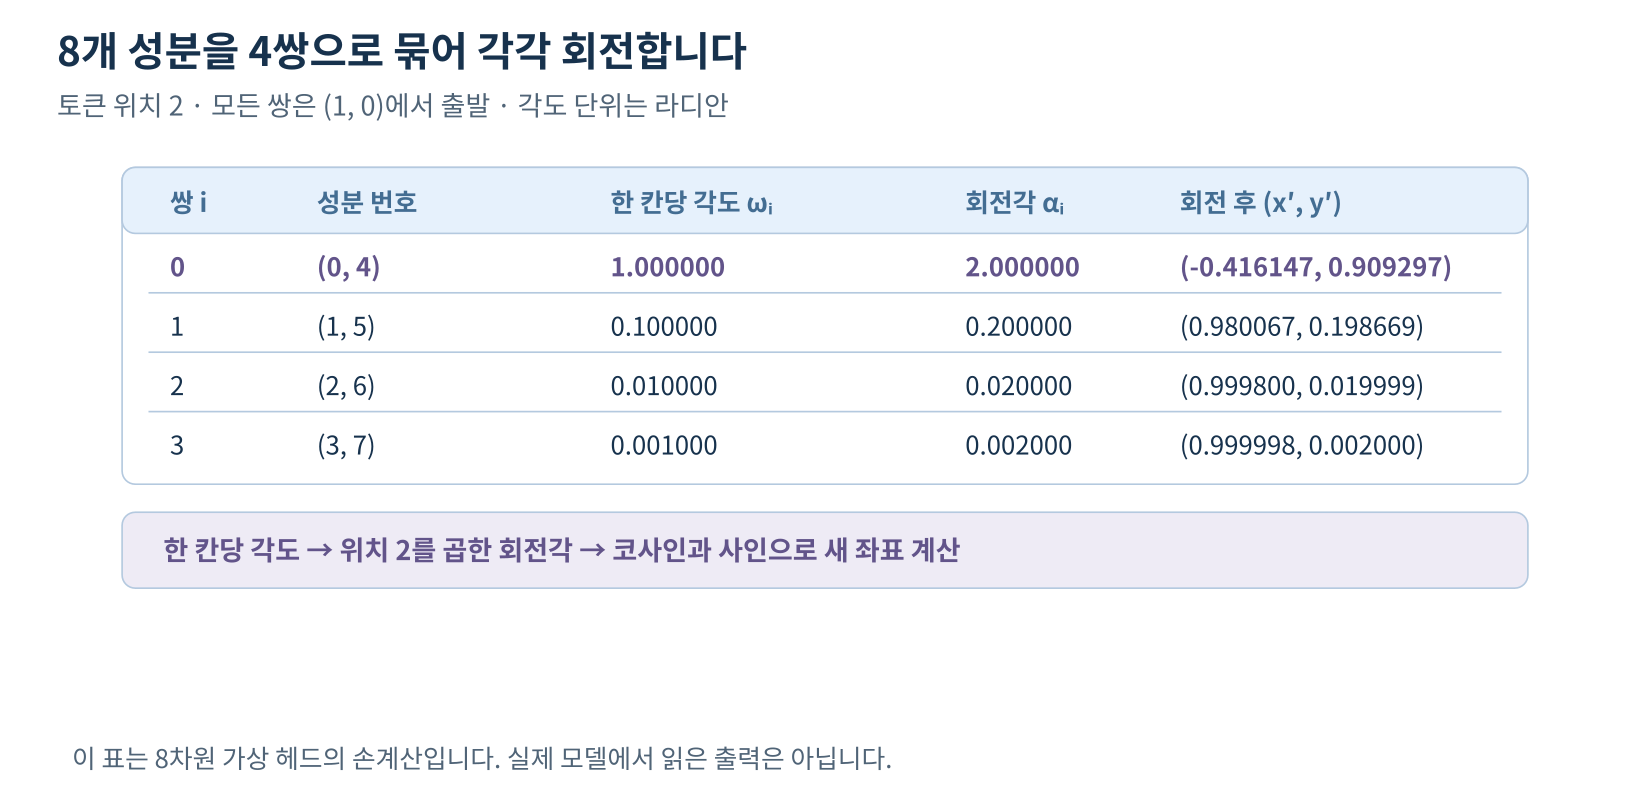

**③ 결과는 어디에 넣을까요?** 각 쌍의 새 가로값은 앞 절반으로, 새 세로값은 뒤 절반으로 돌려놓습니다. 예를 들어 첫째 쌍은 0번과 4번, 마지막 쌍은 3번과 7번에 넣습니다. 원래 성분 번호 순서로 적으면 약 `(−0.416147, 0.980067, 0.999800, 0.999998, 0.909297, 0.198669, 0.019999, 0.002000)`입니다. 각도가 가장 작은 마지막 쌍은 회전 전 `(1, 0)`에서 거의 움직이지 않았습니다.

**왜 빠른 쌍과 느린 쌍을 같이 쓸까요?** 시곗바늘은 한 바퀴를 돌면 같은 방향을 가리킵니다. 그래서 방향만 보면 한 바퀴를 더 돌았는지 알 수 없습니다. RoPE에서도 빠르게 도는 쌍 하나만 보면, 서로 다른 토큰 간격이 비슷하게 보일 수 있습니다.

앞의 네 쌍 중 첫째와 둘째 쌍으로 **Q와 K가 1칸 떨어진 경우와 20칸 떨어진 경우**를 비교해 봅시다. 위치에 따른 회전 차이만 보려고, 회전 전 Q와 K는 같은 방향이라고 놓겠습니다.

- **첫째 쌍은 빠르게 돕니다.** 한 칸당 1 rad씩 돌므로, Q와 K가 1칸 떨어지면 회전각 차이는 1 rad, 20칸 떨어지면 20 rad입니다. 한 바퀴가 2π rad이므로 20 rad는 세 바퀴를 돌고도 `20 − 3 × 2π ≈ 1.15 rad`만큼 더 돈 각도입니다. 한 바퀴를 돌 때마다 같은 방향으로 돌아오므로, 마지막 방향을 비교하면 **1 rad와 약 1.15 rad**로 서로 비슷합니다.
- **둘째 쌍은 느리게 돕니다.** 한 칸당 0.1 rad씩 돌므로, 1칸이면 회전각 차이는 0.1 rad, 20칸이면 `20 × 0.1 = 2 rad`입니다. 2 rad는 한 바퀴(약 6.28 rad)보다 작아 출발 방향으로 돌아오지 않습니다. 마지막 방향을 비교하면 **0.1 rad와 2 rad**로 차이가 뚜렷합니다.

빠른 쌍은 한 칸만 바뀌어도 많이 돌고, 느린 쌍은 덜 돌아 여러 칸에 걸친 차이를 보완합니다. RoPE는 이렇게 **쌍마다 다른 속도로 돌려, 한 쌍에서 비슷해 보이는 간격도 다른 쌍의 내적에 다르게 반영되게** 합니다. 이것이 모든 간격을 언제나 구별하거나 가까운 토큰에 항상 높은 점수를 준다는 뜻은 아닙니다.

**실제 SmolLM2에서는** 한 헤드의 64개 성분을 `(0, 32)`, `(1, 33)`, …, `(31, 63)`의 32쌍으로 묶습니다. 같은 쌍에서는 Q와 K에 같은 한 칸당 각도를 쓰고, 각자 **자기 위치 번호**를 곱합니다. 위 표는 방법을 보여 주는 8차원 손계산이며 실제 모델의 실행 결과와는 별개입니다.

**왜 이렇게 할까요?** 비슷한 내용인지 비교하는 것에 더해, 어떤 토큰이 다른 토큰보다 앞인지 뒤인지, 몇 칸 떨어졌는지도 점수에 반영하기 위해서입니다. GPT-2도 그런 관계를 학습할 수 있지만, RoPE에서는 **각 벡터에 절대 위치(absolute position)로 회전을 주면 두 벡터의 내적에는 상대 위치(relative position)가 반영**됩니다. 두 화살표의 사이 각도가 왜 중요한지는 다음 실습에서 그림으로 확인합니다. 이 성질이 더 긴 문맥에서 성능을 보장하는 것은 아닙니다. [Su 외의 RoFormer 논문 §3.2](https://arxiv.org/html/2104.09864#S3.SS2)

**이 실습이 확인하는 범위:** SmolLM2 보고서는 Llama 계열 설계를 바탕으로 했다고 설명합니다. 위 내용은 선행 연구에서 이 방식을 제안하고 사용한 이유입니다. 보고서에는 135M 모델에서 세 요소를 하나씩 교체해 다시 학습한 비교 결과가 없으므로, 이 실습의 구조 확인과 회전 계산을 성능 향상의 증명으로 해석하지 않습니다. [Llama 논문 §2.2](https://arxiv.org/pdf/2302.13971#page=3) · [SmolLM2 보고서 §6](https://arxiv.org/html/2502.02737#S6)


### 코드 설명: 위치 정보를 Q와 K의 회전으로 반영

앞에서 손으로 Q 벡터 하나를 회전시켰습니다. 이제 SmolLM2가 실제 첫 번째 블록에서 만든 Q·K를 가져와 **회전 결과를 두 가지 방법으로** 구합니다. 하나는 모델 구현의 함수에 맡기고, 다른 하나는 같은 입력에 코사인·사인 수식을 직접 적용합니다. 두 결과가 같은지, 그리고 돌리기 전후에 벡터 길이가 유지되는지 확인하는 실습입니다. 여기서는 V를 회전하거나 어텐션 점수까지 계산하지 않습니다.

헤드 축을 나누고 토큰 축과 교환하는 것은 성분값을 바꾸는 계산이 아니라 배열을 읽는 순서의 변경입니다. 같은 위치의 cos·sin은 모든 헤드에 공유됩니다. 이번 구현은 앞·뒤 절반을 성분쌍으로 묶으므로 앞의 회전 그림과 코드의 짝짓기를 함께 읽으세요.

예를 들어 세 번째 토큰의 다섯 번째 Q 헤드는 축 교환 전 `[0, 2, 4, :]`, 교환 후 `[0, 4, 2, :]`로 꺼냅니다. `.transpose(1, 2)`는 토큰 축과 헤드 축을 맞바꾸며, 그 벡터의 64개 성분값은 그대로입니다.

**수치 비교 기준: RoPE 수식과 길이 보존의 비교**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

수식 비교의 기준은 직접 계산한 `q_manual`, `k_manual`이며 `atol=rtol=1e-6`입니다. 기준 성분의 절댓값이 1이면 허용 차이는 0.000002입니다(계산 설명용 예). 길이 비교의 기준은 **회전 후** `q_rot.norm(...)`, `k_rot.norm(...)`이고 `atol=rtol=1e-5`입니다. 기준 길이가 10이면 0.00011까지 허용합니다(계산 설명용 예). 성분의 일치와 벡터 길이 보존은 다른 대상에 다른 오차 기준을 적용한 검사입니다.


In [5]:
head_dim = first.self_attn.head_dim
# 폭을 헤드당 64로 나눈 뒤 토큰·헤드 축을 교환합니다: (1,T,9,64) → (1,9,T,64).
q = observed["q_raw"].view(1, T, model.config.num_attention_heads, head_dim).transpose(1, 2)
# K는 3개 KV 헤드입니다. 성분값을 바꾸지 않고 축만 (1,3,T,64)로 정돈합니다.
k = observed["k_raw"].view(1, T, model.config.num_key_value_heads, head_dim).transpose(1, 2)
# 동일한 순전파에서 저장한 회전 계수입니다. 다른 입력의 위치 계수를 섞지 않습니다.
cos, sin = observed["cos"], observed["sin"]
# 앞·뒤 절반의 성분쌍 (a,b)을 (-b,a)로 바꿀 보조 연산입니다.
def half_rotation(x):
    # 마지막 축을 두 절반으로 나눕니다. 앞·뒤 절반의 같은 인덱스가 한 회전쌍입니다.
    half = x.shape[-1] // 2
    # 이 구현의 차원 짝짓기에 맞춰 두 절반을 교환하고 한쪽 부호를 바꿉니다.
    return torch.cat([-x[..., half:], x[..., :half]], dim=-1)
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    q_rot, k_rot = apply_rotary_pos_emb(q, k, cos, sin)
    # 헤드 축을 하나 추가한 cos·sin을 모든 헤드에 공유하여 회전식을 적용합니다.
    q_manual = q * cos.unsqueeze(1) + half_rotation(q) * sin.unsqueeze(1)
    # Q와 같은 위치 계수를 K의 세 헤드에도 공유합니다. V에는 이 회전을 적용하지 않습니다.
    k_manual = k * cos.unsqueeze(1) + half_rotation(k) * sin.unsqueeze(1)
assert head_dim == 64
# 기준 b = q_manual; 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(q_rot, q_manual, atol=1e-6, rtol=1e-6)
# 기준 b = k_manual; 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(k_rot, k_manual, atol=1e-6, rtol=1e-6)
# 마지막 64개 성분의 벡터 길이를 비교합니다. 성분값 자체는 회전으로 달라질 수 있습니다.
# 기준 b = q_rot.norm(dim=-1); 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(q.norm(dim=-1), q_rot.norm(dim=-1), atol=1e-5, rtol=1e-5)
# 기준 b = k_rot.norm(dim=-1); 원소별 허용 차이 = 1e-05 + 1e-05 × |b|.
assert torch.allclose(k.norm(dim=-1), k_rot.norm(dim=-1), atol=1e-5, rtol=1e-5)
print("Actual Q / K:", tuple(q.shape), tuple(k.shape))
print("Actual cos / sin:", tuple(cos.shape), tuple(sin.shape))
print("Q formula max difference:", (q_rot - q_manual).abs().max().item())
print("Q norm max difference:", (q.norm(dim=-1) - q_rot.norm(dim=-1)).abs().max().item())
print("K norm max difference:", (k.norm(dim=-1) - k_rot.norm(dim=-1)).abs().max().item())
print("[PASS] 실제 Q/K RoPE 수식·길이 유지")

Actual Q / K: (1, 9, 6, 64) (1, 3, 6, 64)
Actual cos / sin: (1, 6, 64) (1, 6, 64)
Q formula max difference: 0.0
Q norm max difference: 9.5367431640625e-07
K norm max difference: 4.76837158203125e-07
[PASS] 실제 Q/K RoPE 수식·길이 유지


### 출력 설명: 방향을 돌려도 길이가 그대로인가요?

- Q의 `(1, 9, 6, 64)`와 K의 `(1, 3, 6, 64)`는 차례대로 **문장 × 헤드 × 토큰 위치 × 헤드당 성분**입니다. K 헤드 수가 적은 것은 GQA의 특징이며 오류가 아닙니다. cos·sin의 `(1, 6, 64)`에는 헤드 축이 없고 같은 위치의 회전값이 헤드들에 공유됩니다.
- Q 수식 차이 0은 직접 쓴 회전식과 라이브러리 구현의 결과가 일치했다는 뜻입니다. Q 길이 차이는 약 0.000000954, K는 약 0.000000477입니다. 이는 벡터 **길이** 비교의 반올림 수준 차이이며, 회전 전후 성분이 같다는 뜻은 아닙니다.
- PASS는 Q와 K의 수식 일치 및 길이 보존을 허용오차 내에서 검사합니다. 이 셀만으로 장문 성능이나 모든 위치의 어텐션 점수가 같다고 결론 내리지는 않습니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-06, rtol=1e-06`, `atol=1e-05, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 6. 같은 Q/K의 위치만 함께 옮기면?

**무엇을 비교할까요?** 문장에서 두 토큰 사이가 한 칸이라면, 두 토큰이 문장 앞에 있든 뒤에 있든 그 간격은 한 칸입니다. 그렇다면 같은 Q와 K에 RoPE를 적용할 때 **위치 번호만 함께 바꾸면** 두 벡터의 내적은 어떻게 될까요?

**먼저 성분 한 쌍만 손으로 계산해 봅시다.** 앞의 회전 예시처럼 Q와 K에서 성분 두 개씩만 보고, 회전 전 좌표를 둘 다 `(1, 0)`으로 고정합니다. 두 화살표는 오른쪽을 향하고 길이는 1입니다. 이 쌍은 토큰 위치 한 칸당 30°씩 돌린다고 가정합니다. 그러면 각 화살표를 돌리는 각도는 **자기 위치 번호 × 30°**이고, 두 화살표의 내적은 `1 × 1 × cos(사이 각도)`입니다.

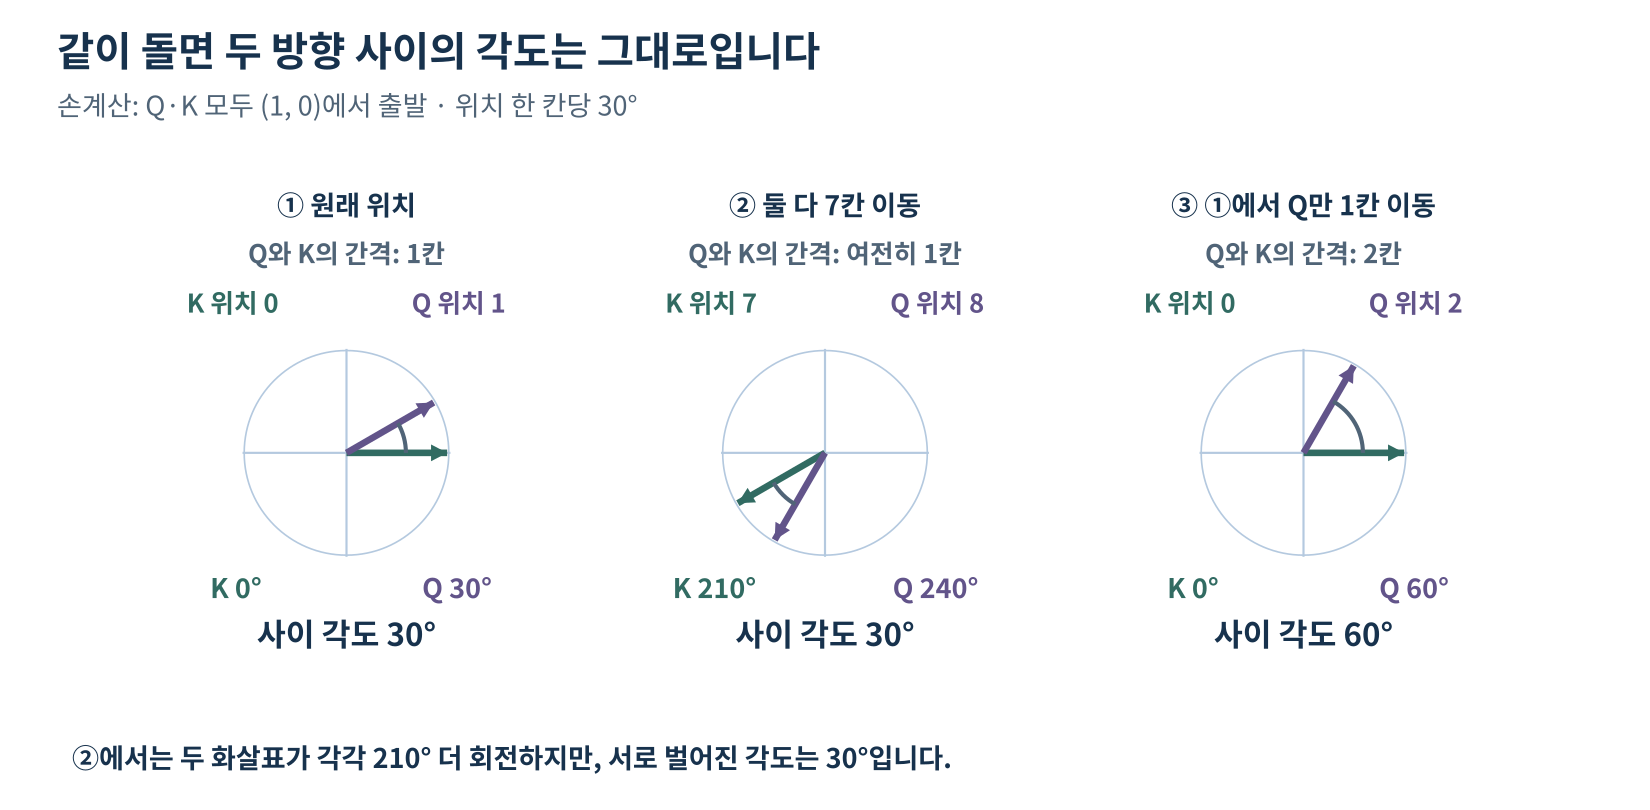

| 비교 | 위치 번호 (Q, K) | 회전 후 방향 (Q, K) | 사이 각도 | 내적 |
|---|---|---|---|---|
| ① 원래 위치 | (1, 0) | (30°, 0°) | 30° | 약 0.866 |
| ② 둘 다 7칸 이동 | (8, 7) | (240°, 210°) | 30° | 약 0.866 |
| ③ 원래 위치에서 Q만 1칸 이동 | (2, 0) | (60°, 0°) | 60° | 0.500 |

**②에서 왜 그대로일까요?** ①과 비교하면 Q도 K도 `7 × 30° = 210°`만큼 더 돌았습니다. 가리키는 방향은 둘 다 달라졌지만, Q와 K 사이의 각도는 `30° − 0° = 240° − 210° = 30°`입니다. 반대로 ③에서는 Q만 30° 더 돌아 사이 각도가 60°로 벌어집니다. 즉, **둘을 함께 돌리는 것**과 **둘 사이의 각도를 바꾸는 것**은 다릅니다.

**실제 코드에서는 무엇을 할까요?** 위의 그림과 표는 2차원 손계산입니다. 실습에서는 SmolLM2의 같은 Q·K 벡터(각각 64개 성분)를 고정하고 ①과 ②만 비교합니다. 쌍마다 한 칸당 각도는 다르지만, **같은 쌍 안에서는** 위치를 똑같이 옮긴 Q와 K가 같은 각도만큼 더 돕니다. 그래서 32쌍의 내적을 합한 전체 내적도 반올림 오차 범위에서 같습니다. 문장 앞에 토큰을 실제로 추가하거나 모델의 확률이 같아지는지 시험하는 셀은 아닙니다.


### 코드 설명: 절대 위치를 함께 옮겨 상대 간격 유지하기

바로 앞 셀의 회전 전 `q`, `k`는 그대로 두고, **회전 계수를 만드는 위치 번호만** 바꿉니다. 원래 위치와 공통 이동 위치에서 각각 같은 Q 벡터 하나와 같은 K 벡터 하나를 골라 내적을 비교합니다.

처음에는 Q의 위치가 1, K의 위치가 0입니다. 두 위치에 똑같이 7을 더하면 8과 7이 되어 간격은 여전히 1입니다. 회전 전 벡터의 값은 바꾸지 않았으므로, 두 경우의 내적을 비교하면 위치를 함께 옮긴 효과만 확인할 수 있습니다.

**수치 비교 기준: 회전 계수와 내적의 비교**

`allclose(a, b)`는 두 번째 인자 `b`를 기준으로 모든 성분에서 다음 조건을 검사합니다: $|a-b| \leq \mathrm{atol} + \mathrm{rtol}\,|b|$. `atol`은 절대 허용오차, `rtol`은 기준값 크기에 비례한 상대 허용오차입니다.

원래 회전 계수의 기준은 관찰한 `cos`, `sin`이며 `atol=rtol=1e-6`입니다. 기준값 0에서는 0.000001, 절댓값 1에서는 0.000002까지 허용합니다. 내적 비교는 이동 후 값 `dot_shifted`가 기준이며 `atol=1e-4`, `rtol=1e-5`입니다. 저장된 기준 내적 약 22.094에서는 허용 차이가 약 **0.00032094**입니다. 출력된 절대 차이가 이 합산 기준 안에 있는지를 보아야 하며, 절대오차 항 0.0001만을 최종 한계로 읽지 않습니다.


In [6]:
# 문장 축을 가진 위치 번호입니다. 입력 토큰의 순서를 바꾸지는 않습니다.
positions = torch.arange(T, device=device).unsqueeze(0)
# 내용 벡터는 고정하고 두 위치에 같은 이동량을 더해 상대 간격을 유지합니다.
shift = 7
# 학습용 기울기를 기록하지 않고 현재 가중치로 계산합니다.
with torch.inference_mode():
    # 첫 텐서는 자료형 등의 기준이고 회전 각도는 위치 번호와 모델 설정으로 정합니다.
    base_cos, base_sin = model.model.rotary_emb(observed["norm_output"], positions)
    shift_cos, shift_sin = model.model.rotary_emb(observed["norm_output"], positions + shift)
    # 이미 회전한 값이 아닌 원래 Q/K에 이동한 위치의 회전을 적용합니다.
    q_shift, k_shift = apply_rotary_pos_emb(q, k, shift_cos, shift_sin)
# 원래 위치로 다시 만든 계수가 실제 모델 실행에서 사용한 계수와 일치하는지 먼저 확인합니다.
# 기준 b = cos; 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(base_cos, cos, atol=1e-6, rtol=1e-6)
# 기준 b = sin; 원소별 허용 차이 = 1e-06 + 1e-06 × |b|.
assert torch.allclose(base_sin, sin, atol=1e-6, rtol=1e-6)
# 첫 헤드의 Q 위치 1과 K 위치 0을 고릅니다. 결과는 확률이 아니라 한 쌍의 내적입니다.
dot_before = torch.dot(q_rot[0, 0, 1], k_rot[0, 0, 0])
# 같은 배열 칸을 비교하되 회전에 쓴 위치는 8과 7입니다. 상대 간격은 같습니다.
dot_shifted = torch.dot(q_shift[0, 0, 1], k_shift[0, 0, 0])
# 같은 내용을 같은 거리만큼 이동한 내적만 비교합니다. 문맥을 바꾼 전체 모델 검사는 아닙니다.
# 기준 b = dot_shifted; 원소별 허용 차이 = 0.0001 + 1e-05 × |b|.
assert torch.allclose(dot_before, dot_shifted, atol=1e-4, rtol=1e-5)
print("Q/K positions: (1, 0) -> (8, 7); relative difference = 1")
print("dot before / common shift:", dot_before.item(), dot_shifted.item())
print("absolute difference:", abs(dot_before.item() - dot_shifted.item()))
print("[PASS] 실제 고정 Q/K의 공통 위치 이동 내적 유지")
print("[PASS] Lesson 04 완료")

Q/K positions: (1, 0) -> (8, 7); relative difference = 1
dot before / common shift: 22.09392738342285 22.09392738342285
absolute difference: 0.0
[PASS] 실제 고정 Q/K의 공통 위치 이동 내적 유지
[PASS] Lesson 04 완료


### 출력 설명: 위치 번호가 바뀌었는데 같은 점수가 나왔나요?

- Q/K 위치를 각각 1·0에서 8·7로 옮겨도 상대 간격은 1입니다. 내용 벡터를 그대로 두고 두 회전 위치에 같은 7을 더한 비교입니다.
- 두 내적은 모두 약 22.094이며, 이 한 쌍의 절대 차이는 0입니다. 내적은 회전된 벡터의 곱을 더한 값으로, 아직 마스크·스케일링·softmax를 적용한 어텐션 확률이 아닙니다.
- PASS는 이 고정 Q/K 쌍에서 공통 위치 이동 전후 내적이 허용오차 안에서 같음을 확인합니다. 실제 문장 앞에 일곱 토큰을 붙여 전체 모델을 다시 실행한 실험은 아니므로, 문맥이 달라져도 출력이 같다는 뜻으로 확대하지 않습니다.

**판정 기준 연결:** 이 셀의 비교는 `atol=1e-06, rtol=1e-06`, `atol=0.0001, rtol=1e-05`를 사용합니다. 위 **코드 설명의 수치 비교 기준**에서 각 비교의 두 번째 인자와 실제 허용 차이 계산을 확인하세요. 출력의 최대 절대 차이와 `atol`만 비교하는 방식이 아니라, 각 기준값에 따른 `atol + rtol × |기준값|`으로 판정합니다.


## 정리와 자기 점검
- RMSNorm: 평균을 빼지 않고 RMS 규모와 학습 가중치로 정돈합니다.
- SwiGLU: 두 투영 경로 중 하나에 SiLU를 적용하고 원소별로 곱합니다.
- RoPE: 위치에 따라 Q/K를 회전시켜 내적에 상대 위치 정보가 반영되게 합니다.

모두 실제 모델의 첫 블록에서 확인했으며 전체 30개 블록 forward도 실행했습니다. 다시 확인할 때는 커널을 재시작하고 처음부터 실행하세요. 실행하지 않은 셀은 PASS가 아닙니다.


### 자기 점검 질문

1. RMSNorm의 출력 평균이 0이 아니어도 오류라고 할 수 없는 이유는 무엇인가요?

   **핵심 답과 이유:** RMSNorm은 성분 평균을 빼지 않고 제곱평균에 따른 크기를 조정한 뒤 학습된 성분별 배율을 곱하기 때문입니다. 이번 출력 평균도 0이 아니며, 성공 여부는 평균이 아니라 실제 모듈 출력과 재구성 값의 일치로 확인합니다.

2. RoPE 공통 이동 검사는 문장 전체를 바꾸어 실행한 실험과 어떻게 다른가요?

   **핵심 답과 이유:** 이 실험은 이미 얻은 Q/K 내용 벡터를 고정하고 두 위치 번호에 같은 값을 더해 회전과 내적만 비교합니다. 문장 전체를 바꾸면 토큰과 문맥에서 만들어지는 내용 벡터도 달라질 수 있으므로, 그때의 모델 출력까지 같다는 뜻은 아닙니다.


## 참고 자료
- Zhang & Sennrich, [Root Mean Square Layer Normalization](https://arxiv.org/abs/1910.07467), §4 RMSNorm. 구현의 epsilon과 학습 가중치를 포함해 대조했습니다.
- Shazeer, [GLU Variants Improve Transformer](https://arxiv.org/abs/2002.05202), §2 GLU and Variants의 SwiGLU 및 FFN 정의.
- Su 외, [RoFormer](https://arxiv.org/abs/2104.09864), §3.2.1 2D case, §3.2.2 General form, §3.3 Properties of RoPE.
- Allal 외, [SmolLM2: When Smol Goes Big](https://arxiv.org/abs/2502.02737), §6 SmolLM2 135M and 360M. 논문의 주된 1.7B 모델과 이번 135M을 구분합니다.
- [버전 고정 Llama 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/llama/modeling_llama.py): LlamaRMSNorm, LlamaMLP, LlamaRotaryEmbedding, apply_rotary_pos_emb, LlamaAttention. 실제 설치 버전도 셀 1에 출력합니다.
- [GPT-2 기술 보고서](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) §2.3, [GPT-2 구현](https://huggingface.co/docs/transformers/v5.23.0/en/model_doc/gpt2): 앞 교시 구조 비교 근거.
- [SmolLM2 공식 모델 카드](https://huggingface.co/HuggingFaceTB/SmolLM2-135M), [고정 config](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json).
- 모델 `HuggingFaceTB/SmolLM2-135M`, revision `93efa2f097d58c2a74874c7e644dbc9b0cee75a2`. 가중치 269,060,552바이트, SHA256 `80521b40281d6ce74e35c9282c22539e75aa0ac8578892b2a59955ef78d55da1`.